# 📘 Cell 1 — Setup + Data Load

**목적**: 환경 세팅(경로, 폰트, 툴킷 import), 병합본(`merged_dataset.pkl`) + 참조 데이터셋(`aihub_extra_merged_clean_before_remap.csv`) 로드 및 shape 검증.

**전제 조건**:
- `02_eda.ipynb`는 `D:\pill_detection\eda\` 에 위치
- `merged_dataset.pkl`도 같은 `eda\` 폴더에 존재 (01_merge에서 생성)
- `aihub_extra_merged_clean_before_remap.csv`도 `eda\` 폴더에 존재 (Cell 5 비교용, 없으면 자동 스킵)
- 툴킷은 `D:\pill_detection\_toolkit\` 에 위치

**검증 기준**:
- 병합본: 41,225행 × 76컬럼
- 참조 데이터셋: 40,081행 × 43컬럼 (있을 때만)
- 필수 컬럼 전부 존재
- 툴킷 import 성공 + 한글 폰트 설정 성공

In [19]:
# ===== Cell 1: Setup + Data Load =====

import warnings
warnings.filterwarnings('ignore', category=UserWarning, module='matplotlib')
warnings.filterwarnings('ignore', message='.*Glyph.*missing from font.*')

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----- 경로 설정 -----
NOTEBOOK_DIR = Path().resolve()               # D:\pill_detection\eda
PROJ_ROOT = NOTEBOOK_DIR.parent                # D:\pill_detection
TOOLKIT_DIR = PROJ_ROOT / "_toolkit"
DATA_DIR = PROJ_ROOT / "data"
FIG_DIR = NOTEBOOK_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

PKL_PATH = NOTEBOOK_DIR / "merged_dataset.pkl"
REF_CSV_PATH = NOTEBOOK_DIR / "aihub_extra_merged_clean_before_remap.csv"

# ----- 툴킷 import -----
if not TOOLKIT_DIR.exists():
    raise FileNotFoundError(f"Toolkit not found: {TOOLKIT_DIR}")
sys.path.insert(0, str(TOOLKIT_DIR))

from utils.eda_common import quick_audit, describe_plus, null_report, detect_duplicates
from utils.viz_helpers import setup_korean_font, plot_class_longtail, plot_missing_bar, plot_train_test_distribution

# ----- 한글 폰트 -----
setup_korean_font()

# ----- 병합본 로드 -----
if not PKL_PATH.exists():
    raise FileNotFoundError(f"Merged pkl not found: {PKL_PATH}")
df = pd.read_pickle(PKL_PATH)
print("=" * 60)
print(f"[merged_dataset.pkl]")
print("=" * 60)
print(f"  shape        : {df.shape}")
print(f"  size         : {PKL_PATH.stat().st_size / 1024 / 1024:.2f} MB")
print(f"  expected     : (41225, 76)")
print(f"  match        : {df.shape == (41225, 76)}")

# 핵심 컬럼 존재 검증
REQUIRED_COLS = [
    'source', 'series', 'combo', 'kcode_folder', 'image_file', 'image_exists',
    'angle', 'ann_id', 'category_id_raw', 'bbox_raw', 'bbox_valid',
    'bbox_x', 'bbox_y', 'bbox_w', 'bbox_h', 'area_raw',
    'cat_id', 'cat_name', 'parse_error',
]
missing = [c for c in REQUIRED_COLS if c not in df.columns]
if missing:
    print(f"  ⚠️ 필수 컬럼 누락: {missing}")
else:
    print(f"  ✅ 필수 컬럼 {len(REQUIRED_COLS)}개 전부 존재")

# ----- 참조 데이터셋 로드 (Cell 5 비교용) -----
if REF_CSV_PATH.exists():
    df_ref = pd.read_csv(REF_CSV_PATH)
    print("\n" + "=" * 60)
    print(f"[aihub_extra_merged_clean_before_remap.csv]")
    print("=" * 60)
    print(f"  shape        : {df_ref.shape}")
    print(f"  expected     : (40081, 43)")
    print(f"  match        : {df_ref.shape == (40081, 43)}")
else:
    df_ref = None
    print(f"\n[aihub_extra_merged_clean_before_remap.csv]")
    print(f"  ⚠️ 파일 없음: {REF_CSV_PATH}")
    print(f"  → Cell 5 비교 분석 스킵 예정")

# ----- 경로 요약 출력 -----
print("\n" + "=" * 60)
print("[경로 요약]")
print("=" * 60)
print(f"  PROJ_ROOT    : {PROJ_ROOT}")
print(f"  DATA_DIR     : {DATA_DIR}  (exists={DATA_DIR.exists()})")
print(f"  FIG_DIR      : {FIG_DIR}")
print(f"  TOOLKIT_DIR  : {TOOLKIT_DIR}")

✅ 한글 폰트 설정: Malgun Gothic
[merged_dataset.pkl]
  shape        : (41225, 76)
  size         : 46.74 MB
  expected     : (41225, 76)
  match        : True
  ✅ 필수 컬럼 19개 전부 존재

[aihub_extra_merged_clean_before_remap.csv]
  shape        : (40081, 43)
  expected     : (40081, 43)
  match        : True

[경로 요약]
  PROJ_ROOT    : D:\pill_detection
  DATA_DIR     : D:\pill_detection\data  (exists=True)
  FIG_DIR      : D:\pill_detection\eda\figures
  TOOLKIT_DIR  : D:\pill_detection\_toolkit


# 📘 Cell 2 — L0 Sanity: 76컬럼 기본 감사 (quick_audit)

**목적**: 툴킷의 `quick_audit`으로 76컬럼 전수 스캔. 각 컬럼별 dtype/결측률/고유값 수/샘플값 + 자동 플래그(constant/high_missing/high_cardinality/low_variance) 확인.

**설계 주의사항**:
- `quick_audit`은 `nunique()`를 호출하므로 list 타입 컬럼(`bbox_raw`, `segmentation` 등)에서 `TypeError: unhashable type: 'list'` 가능
- 방어: list 컬럼은 str 변환 후 audit, 또는 해당 컬럼만 제외
- 76컬럼 전부 출력 시 pandas 기본 잘림 → `max_rows=100` 세팅

**검증 기준**:
- 에러 없이 실행
- `parse_error` 컬럼 결측률 확인 (324건 이슈 / 41225 = 0.79% 결측 ❌ — 사실은 이슈 있는 건만 값 있고 정상은 NaN이므로 결측률 ≈ 99.21%가 정상)
- `series`, `source`, `cat_name` 같은 범주형 컬럼 dtype 확인
- 자동 플래그 결과 출력

In [20]:
# ===== Cell 2: L0 Sanity — 76컬럼 기본 감사 =====

# ----- unhashable 컬럼 전수 탐지 (try/except로 정직하게) -----
unhashable_cols = []
for col in df.columns:
    try:
        df[col].nunique()
    except TypeError:
        unhashable_cols.append(col)

print(f"[unhashable 컬럼] {len(unhashable_cols)}개: {unhashable_cols}")
print(f"  → quick_audit에서 제외하고 별도 요약\n")

# ----- quick_audit 실행 (unhashable 컬럼 제외) -----
audit_cols = [c for c in df.columns if c not in unhashable_cols]
audit = quick_audit(df[audit_cols])

# 전체 출력용 pandas 세팅
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 60)
pd.set_option('display.width', 200)

print("=" * 80)
print(f"[quick_audit 결과] {len(audit)}컬럼 (unhashable {len(unhashable_cols)}개 제외)")
print("=" * 80)
print(audit)

# ----- 플래그별 요약 -----
print("\n" + "=" * 80)
print("[자동 플래그 요약]")
print("=" * 80)
flag_types = ['constant', 'high_missing', 'high_cardinality', 'low_variance']
for ft in flag_types:
    flagged = audit[audit['flag'].str.contains(ft, na=False)]
    print(f"  {ft:20s}: {len(flagged)}개 — {list(flagged.index)[:10]}{'...' if len(flagged) > 10 else ''}")

# ----- unhashable 컬럼은 별도 요약 -----
print("\n" + "=" * 80)
print("[unhashable 컬럼 별도 요약]")
print("=" * 80)
for col in unhashable_cols:
    non_null = df[col].dropna()
    null_count = df[col].isna().sum()
    null_pct = null_count / len(df) * 100
    
    # 첫 값 타입 샘플
    sample_types = set()
    for v in df[col].dropna().head(100):
        sample_types.add(type(v).__name__)
    
    # length 분포 (list/dict류)
    if len(non_null) > 0:
        try:
            lengths = non_null.apply(len)
            len_info = f"len min={lengths.min()} median={lengths.median():.0f} max={lengths.max()}"
        except Exception:
            len_info = "len 계산 불가"
    else:
        len_info = "전부 NaN"
    
    print(f"  {col:20s}: "
          f"non_null={len(non_null):>6,} / null={null_count:>6,} ({null_pct:.2f}%) | "
          f"types={sample_types} | {len_info}")

# ----- parse_error 분포 (324건 확인용) -----
print("\n" + "=" * 80)
print("[parse_error 분포]")
print("=" * 80)
pe_counts = df['parse_error'].value_counts(dropna=False)
print(pe_counts)
print(f"\n  정상 (NaN): {df['parse_error'].isna().sum():,}")
print(f"  이슈 (non-NaN): {df['parse_error'].notna().sum():,}")
print(f"  합계: {len(df):,}  (expected: 41,225)")

[unhashable 컬럼] 3개: ['bbox_raw', 'area_raw', 'segmentation']
  → quick_audit에서 제외하고 별도 요약

[quick_audit 결과] 73컬럼 (unhashable 3개 제외)
                            dtype  n_missing  pct_missing  n_unique  pct_unique                                                sample_values                    flag
source                     object          0         0.00         8        0.02                 [kaggle_train, aihub_ts1_tl1, aihub_ts3_tl3]                        
source_json                object         48         0.12     41177       99.88  [K-001900-016548-019607-029451_json\K-001900\K-001900-01...       high_cardinality 
combo                      object          0         0.00      3619        8.78  [K-001900-016548-019607-029451, K-001900-016548-019607-0...                        
kcode_folder               object         48         0.12       120        0.29                               [K-001900, K-016548, K-019607]                        
image_file                 object          

### 인사이트 (Cell 2)

- **76컬럼 중 unhashable 3개** (`bbox_raw`, `area_raw`, `segmentation`) — `nunique()` 적용 불가, 별도 요약
- **결측 패턴이 parse_error 플래그와 수학적으로 정확히 일치** — 01_merge 무결성 재확증
  - ann_* / cat_* / img_* 군(49건 결측) = orphan_image 48 + json_load_fail 1
  - bbox_* 군(204건 결측) = 49 + bbox_format_error 155
  - image_path(121건 결측) = json_load_fail 1 + orphan_label 120
- **parse_error 324건 breakdown**: bbox_format_error 155 / orphan_label 120 / orphan_image 48 / json_load_fail 1
- **신규 이슈 2건 발견**:
  - 🟡 이슈 L: `iscrowd`에 58548.0 섞임 (COCO 표준은 0/1만) → Cell 4에서 전수 확인
  - 🟡 이슈 M: `area_raw` 타입 혼재 (int 대다수 + list 일부 추정) → Cell 4에서 전수 확인
- **해석 대기**: cat_name 57종 vs img_dl_name 118종 (61종 차이의 의미) → L1(Cell 6~7)
- **전처리 제거 후보**: constant 10개 + low_variance 17개 (학습 피처로 부적합)
- **팀미팅 핵심**: 병합 무결성 확증 + bbox 품질 검증은 Cell 4 / 카테고리 정의 명확화는 Cell 6에서 진행

# 📘 Cell 3 — L0 Sanity: parse_error × image_exists 교차 검증

**목적**: 324건 이슈 각각이 `image_exists` 값과 논리적으로 일치하는지 검증. 정상 40,901건 중 `image_exists=False`가 없는지 확인.

**검증 가설**:
1. `orphan_image` 48건: TS만 있고 라벨 없음 → **image_exists=True**여야 함
2. `orphan_label` 120건: TL만 있고 이미지 없음 → **image_exists=False**여야 함
3. `bbox_format_error` 155건: 라벨 자체는 존재 → **image_exists=True**여야 함
4. `json_load_fail` 1건: JSON 손상, 이미지 불명 → **image_exists=False 또는 NaN**
5. 정상 40,901건: 전부 **image_exists=True**여야 함

**이슈 판정 기준**:
- 가설과 다른 케이스가 있으면 병합 로직 오류 또는 파일 시스템 상태 이슈

In [21]:
# ===== Cell 3: L0 Sanity — parse_error × image_exists 교차 검증 =====

# ----- parse_error 값 정규화 (bbox_format_error, orphan_label, orphan_image, json_load_fail, normal) -----
def classify_pe(v):
    if pd.isna(v):
        return 'normal'
    if isinstance(v, str) and v.startswith('json_load_fail'):
        return 'json_load_fail'
    return v

df['_pe_class'] = df['parse_error'].apply(classify_pe)

# ----- 교차표 -----
print("=" * 80)
print("[parse_error × image_exists 교차표]")
print("=" * 80)
crosstab = pd.crosstab(
    df['_pe_class'], 
    df['image_exists'].fillna('NaN'),
    margins=True, 
    margins_name='Total'
)
print(crosstab)

# ----- 가설 검증 -----
print("\n" + "=" * 80)
print("[가설 검증]")
print("=" * 80)

checks = [
    ('normal',            True,  '정상 → image_exists=True여야 함'),
    ('bbox_format_error', True,  'bbox_format_error → image_exists=True여야 함'),
    ('orphan_image',      True,  'orphan_image (TS만 있음) → image_exists=True여야 함'),
    ('orphan_label',      False, 'orphan_label (TL만 있음) → image_exists=False여야 함'),
]

issues_found = []
for pe_class, expected_exists, desc in checks:
    subset = df[df['_pe_class'] == pe_class]
    total = len(subset)
    match = (subset['image_exists'] == expected_exists).sum()
    mismatch = total - match
    status = '✅' if mismatch == 0 else '❌'
    print(f"  {status} {desc}")
    print(f"     total={total:>5} | match={match:>5} | mismatch={mismatch:>5}")
    if mismatch > 0:
        issues_found.append((pe_class, expected_exists, mismatch))

# ----- json_load_fail 1건 상세 -----
print("\n" + "=" * 80)
print("[json_load_fail 1건 상세]")
print("=" * 80)
jlf = df[df['_pe_class'] == 'json_load_fail']
print(jlf[['source', 'series', 'source_json', 'image_file', 'image_exists']].to_string())

# ----- image_exists=False 전수 확인 -----
print("\n" + "=" * 80)
print("[image_exists=False 전수]")
print("=" * 80)
fe = df[df['image_exists'] == False]
print(f"  총 {len(fe)}건")
print(f"  parse_error 분포:")
print(fe['_pe_class'].value_counts())

# ----- image_exists=NaN 확인 -----
print("\n" + "=" * 80)
print("[image_exists=NaN 전수]")
print("=" * 80)
ne = df[df['image_exists'].isna()]
print(f"  총 {len(ne)}건")
if len(ne) > 0:
    print(ne[['source', 'series', 'source_json', 'image_file', '_pe_class']].to_string())

# ----- 최종 판정 -----
print("\n" + "=" * 80)
print("[최종 판정]")
print("=" * 80)
if not issues_found:
    print("  ✅ 가설 검증 전부 통과 — parse_error ↔ image_exists 논리적 일관성 확인됨")
else:
    print(f"  ❌ {len(issues_found)}개 가설 위반:")
    for pe_class, expected, cnt in issues_found:
        print(f"    - {pe_class}: image_exists={expected} 아닌 레코드 {cnt}건")

# 임시 컬럼 정리
df.drop(columns=['_pe_class'], inplace=True)

[parse_error × image_exists 교차표]
image_exists       False   True  NaN  Total
_pe_class                                  
bbox_format_error      0    155    0    155
json_load_fail         0      0    1      1
normal                 0  40901    0  40901
orphan_image           0     48    0     48
orphan_label         120      0    0    120
Total                120  41104    1  41225

[가설 검증]
  ✅ 정상 → image_exists=True여야 함
     total=40901 | match=40901 | mismatch=    0
  ✅ bbox_format_error → image_exists=True여야 함
     total=  155 | match=  155 | mismatch=    0
  ✅ orphan_image (TS만 있음) → image_exists=True여야 함
     total=   48 | match=   48 | mismatch=    0
  ✅ orphan_label (TL만 있음) → image_exists=False여야 함
     total=  120 | match=  120 | mismatch=    0

[json_load_fail 1건 상세]
              source  series                                                                                           source_json image_file image_exists
28770  aihub_ts6_tl6       6  K-012247-016551-033009-0441

### 인사이트 (Cell 3)

- **parse_error × image_exists 교차 검증 전부 통과** — 4개 가설 전체 mismatch 0건
- **수학적 무결성**:
  - False 120건 = orphan_label 전체 (라벨만 있고 이미지 없음)
  - NaN 1건 = json_load_fail 전체 (JSON 파싱 실패 → 이미지 존재 여부 미판정, 논리적 정상)
  - True 41,104건 = normal 40,901 + bbox_format_error 155 + orphan_image 48
- **json_load_fail 1건 정체**: AI Hub 원본 폴더명에 "오류" 한글 포함 (`K-016551-오류`) — 원본 데이터셋 생성자의 손상 표시 추정. 우리 파이프라인이 정확히 포착
- **학습 가능 후보 확정**: normal 40,901 + bbox_format_error 복구 가능한 일부 = **최대 약 41,056건**
- **학습 제외 확정**: orphan_label 120 + json_load_fail 1 + orphan_image 48 = **169건**
  - orphan_image 48건은 이미지는 있으나 bbox 없음 → 학습 불가. 단, **추론 테스트용 샘플로는 활용 가능**
- **팀미팅 핵심**: 324건 이슈의 논리적 일관성 확증 — 01_merge 병합 로직 전면 신뢰 가능

# 📘 Cell 4 — L0 Sanity: bbox 전수 무결성 검증 (이슈 A/B/D/L/M 통합)

**목적**: 정상(normal) + bbox_format_error 레코드의 bbox 무결성 전수 검증. 이전 Kaggle-only EDA에서 확정된 이슈 A/C/D를 병합본 전체(41,225건) 기준으로 재검증 + Cell 2에서 발견한 이슈 L/M 실태 파악.

**검증 플래그**:
- **A**: bbox 이미지 경계 초과 (x<0 or y<0 or x+w>img_w or y+h>img_h)
- **B**: area_raw ≠ w×h (10% 이상 차이)
- **D**: bbox 음수/0 크기 (w≤0 or h≤0)
- **L**: iscrowd ∉ {0, 1} (COCO 표준 위반)
- **M**: area_raw 타입 이상 (int 아닌 값)

**대상**:
- 정상 40,901 (이슈 0 기대)
- bbox_format_error 155 (이슈 다수 기대, 플래그 근원)

**방법론**: 툴킷 `detection_utils.bbox_sanity`의 로직을 DataFrame에 맞게 적용 (COCO dict 역변환 낭비 회피)

**출력**:
- 플래그별 건수 + source별 분포
- 겹치는 이슈 교집합 (A ∩ B 등)
- 이슈 레코드 샘플 10건 (파일명 + bbox + 왜 이슈인지)

In [22]:
# ===== Cell 4: L0 Sanity — bbox 전수 무결성 검증 =====

# ----- 대상 필터 (bbox 있는 레코드) -----
# parse_error NaN (정상) + bbox_format_error (bbox 이슈 플래그 근원)
target_mask = df['parse_error'].isna() | (df['parse_error'] == 'bbox_format_error')
df_bbox = df[target_mask].copy()
print(f"[대상] parse_error NaN + bbox_format_error = {len(df_bbox):,}건")
print(f"  기대: 40,901 + 155 = 41,056")
print(f"  실제: {len(df_bbox):,}")
print(f"  match: {len(df_bbox) == 41056}\n")

# ----- 이미지 크기 상수 (Cell 2에서 전수 확인: img_width=976, img_height=1280 constant) -----
IMG_W = 976
IMG_H = 1280

# ----- 이슈 A: bbox 경계 초과 -----
# bbox_* 가 NaN이면 판정 불가 → 제외
bbox_valid_rows = df_bbox[df_bbox['bbox_x'].notna() & df_bbox['bbox_y'].notna() & 
                          df_bbox['bbox_w'].notna() & df_bbox['bbox_h'].notna()].copy()
print(f"[bbox 4값 전부 non-null] {len(bbox_valid_rows):,}건")

flag_A = (
    (bbox_valid_rows['bbox_x'] < 0) |
    (bbox_valid_rows['bbox_y'] < 0) |
    ((bbox_valid_rows['bbox_x'] + bbox_valid_rows['bbox_w']) > IMG_W + 1) |  # +1 rounding tolerance
    ((bbox_valid_rows['bbox_y'] + bbox_valid_rows['bbox_h']) > IMG_H + 1)
)
issue_A = bbox_valid_rows[flag_A]
print(f"\n[이슈 A: bbox 경계 초과] {len(issue_A)}건")
if len(issue_A) > 0:
    print(issue_A[['source', 'series', 'image_file', 'bbox_x', 'bbox_y', 'bbox_w', 'bbox_h']].head(10).to_string())

# ----- 이슈 D: bbox 음수/0 크기 -----
flag_D = (bbox_valid_rows['bbox_w'] <= 0) | (bbox_valid_rows['bbox_h'] <= 0)
issue_D = bbox_valid_rows[flag_D]
print(f"\n[이슈 D: bbox 음수/0 크기] {len(issue_D)}건")
if len(issue_D) > 0:
    print(issue_D[['source', 'series', 'image_file', 'bbox_x', 'bbox_y', 'bbox_w', 'bbox_h']].head(10).to_string())

# ----- 이슈 M: area_raw 타입 검증 -----
print(f"\n[이슈 M: area_raw 타입 검증]")
area_types = df_bbox['area_raw'].dropna().apply(type).value_counts()
print(area_types)

# 비-숫자 (list, str 등) 탐지
def is_numeric(v):
    return isinstance(v, (int, float)) and not pd.isna(v)

non_numeric_area = df_bbox[df_bbox['area_raw'].notna() & ~df_bbox['area_raw'].apply(is_numeric)]
print(f"\n  비-숫자 area_raw: {len(non_numeric_area)}건")
if len(non_numeric_area) > 0:
    print(non_numeric_area[['source', 'parse_error', 'image_file', 'area_raw']].head(10).to_string())

# ----- 이슈 B: area_raw ≠ w×h -----
# 숫자형만 대상
numeric_area_rows = bbox_valid_rows[bbox_valid_rows['area_raw'].apply(is_numeric)].copy()
numeric_area_rows['area_computed'] = numeric_area_rows['bbox_w'] * numeric_area_rows['bbox_h']
numeric_area_rows['area_diff_pct'] = (
    (numeric_area_rows['area_raw'].astype(float) - numeric_area_rows['area_computed']).abs() 
    / numeric_area_rows['area_computed'].replace(0, 1) * 100
)
flag_B = numeric_area_rows['area_diff_pct'] > 10  # 10% 이상 차이
issue_B = numeric_area_rows[flag_B]
print(f"\n[이슈 B: area_raw ≠ w×h (10%+ 차이)] {len(issue_B)}건 / 대상 {len(numeric_area_rows):,}건")
if len(issue_B) > 0:
    cols = ['source', 'series', 'image_file', 'bbox_w', 'bbox_h', 'area_raw', 'area_computed', 'area_diff_pct']
    print(issue_B[cols].head(10).to_string())

# ----- 이슈 L: iscrowd ∉ {0, 1} -----
print(f"\n[이슈 L: iscrowd 표준 위반]")
iscrowd_dist = df_bbox['iscrowd'].value_counts(dropna=False)
print(iscrowd_dist)

valid_iscrowd = {0, 1, 0.0, 1.0}
flag_L = df_bbox['iscrowd'].notna() & ~df_bbox['iscrowd'].isin(valid_iscrowd)
issue_L = df_bbox[flag_L]
print(f"\n  iscrowd ∉ {{0, 1}}: {len(issue_L)}건")
if len(issue_L) > 0:
    print(issue_L[['source', 'series', 'image_file', 'iscrowd', 'bbox_x', 'bbox_y', 'bbox_w', 'bbox_h']].head(10).to_string())

# ----- 통합 요약 -----
print("\n" + "=" * 80)
print("[이슈 A/B/D/L/M 통합 요약]")
print("=" * 80)
print(f"  A (경계 초과)     : {len(issue_A):>4}건")
print(f"  B (area 불일치)   : {len(issue_B):>4}건")
print(f"  D (음수/0 크기)   : {len(issue_D):>4}건")
print(f"  L (iscrowd 위반)  : {len(issue_L):>4}건")
print(f"  M (area 타입 이상): {len(non_numeric_area):>4}건")

# ----- source별 분포 -----
print("\n[source별 이슈 분포]")
issue_by_source = pd.DataFrame({
    'A': issue_A.groupby('source').size(),
    'B': issue_B.groupby('source').size(),
    'D': issue_D.groupby('source').size(),
    'L': issue_L.groupby('source').size(),
    'M': non_numeric_area.groupby('source').size(),
}).fillna(0).astype(int)
print(issue_by_source)

# ----- 정상 레코드(parse_error NaN) 중 추가 이슈 탐지 -----
print("\n" + "=" * 80)
print("[정상 레코드(parse_error NaN) 중 추가 이슈 탐지]")
print("=" * 80)
normal_mask = df_bbox['parse_error'].isna()
issue_A_in_normal = len(issue_A[issue_A['parse_error'].isna()])
issue_B_in_normal = len(issue_B[issue_B['parse_error'].isna()])
issue_D_in_normal = len(issue_D[issue_D['parse_error'].isna()])
issue_L_in_normal = len(issue_L[issue_L['parse_error'].isna()])
issue_M_in_normal = len(non_numeric_area[non_numeric_area['parse_error'].isna()])

print(f"  A: {issue_A_in_normal}건 (정상 라벨링 돼 있지만 경계 초과)")
print(f"  B: {issue_B_in_normal}건 (area 불일치)")
print(f"  D: {issue_D_in_normal}건 (음수/0 크기)")
print(f"  L: {issue_L_in_normal}건 (iscrowd 위반)")
print(f"  M: {issue_M_in_normal}건 (area 타입 이상)")
total_add = issue_A_in_normal + issue_D_in_normal + issue_L_in_normal + issue_M_in_normal
print(f"\n  → 정상 레코드 중 추가 필터링 후보 (A/D/L/M 합집합): 최대 {total_add}건")
print(f"  → 참조 CSV 대비 +57건 차이 후보 (Cell 5에서 교차)")

[대상] parse_error NaN + bbox_format_error = 41,056건
  기대: 40,901 + 155 = 41,056
  실제: 41,056
  match: True

[bbox 4값 전부 non-null] 40,901건

[이슈 A: bbox 경계 초과] 58건
              source  series                                            image_file  bbox_x  bbox_y  bbox_w  bbox_h
239     kaggle_train       0         K-003351-016262-018357_0_2_0_2_75_000_200.png  6567.0   625.0   311.0   315.0
1662   aihub_ts1_tl1       1  K-000250-004378-022627-037777_0_2_0_2_90_000_200.png   644.0   851.0   190.0   498.0
1987   aihub_ts1_tl1       1  K-000250-005886-006192-038954_0_2_0_2_70_000_200.png   812.0   185.0   272.0   275.0
3064   aihub_ts1_tl1       1  K-000573-001866-006192-037777_0_2_0_2_70_000_200.png  1098.0   149.0   226.0   446.0
3327   aihub_ts1_tl1       1  K-000573-002483-003743-022627_0_2_0_2_90_000_200.png   729.0   779.0   330.0   322.0
4875   aihub_ts1_tl1       1  K-001866-004378-019552-038954_0_2_0_2_90_000_200.png    77.0   158.0  3131.0   498.0
8111   aihub_ts3_tl3       3  K-00

### 인사이트 (Cell 4)

- **대상**: parse_error NaN + bbox_format_error = 41,056건 (기대치 일치)
- **이슈 A (경계 초과) 58건** — Kaggle 1 + AI Hub 57
  - 극단 사례: bbox_w=3131 (이미지폭 976의 3배)
  - AI Hub 시리즈별 분포(5/7/9/9/8/12/7)가 참조 CSV 부족분과 정확히 일치 → **참조 CSV는 이슈 A 기반 필터링 수행 추정** (Cell 5에서 file_name 단위 확증)
- **이슈 B (area 불일치 10%+) 216건** — Kaggle 1 + AI Hub 215
  - 원본 JSON area 필드 오류. bbox 좌표 자체는 유효
  - YOLO 등 주류 detector는 area 필드 미사용 → 학습 무영향. 03에서 w×h로 재계산
- **이슈 D (음수/0 크기) 0건** — 기존 가설 기각. AI Hub 원본이 양수만 보존
- **이슈 L (iscrowd ∉ {0,1}) 1건** — iscrowd=58548 (원본 JSON 필드 오염). 해당 1건 제외
- **이슈 M (area_raw 타입 list) 2건** — 1건은 bbox_format_error 플래그 중복, 1건은 정상 레코드(area=[33820] 단일원소 list)
- **정상 레코드(40,901) 중 추가 필터링 후보**: A 58 + D 0 + L 1 + M 1 = 최대 60건
- **팀미팅 핵심**:
  - 참조 CSV +57건 차이의 정체가 "이슈 A 필터링"으로 수렴 (Cell 5 확증 대기)
  - 03_preprocessing에서 이슈 A 처리 방식(clip vs 제외) 결정 필요
  - 이슈 B는 area 재계산만 하면 모두 유효 레코드

# 📘 Cell 5 — L0 Sanity: 참조 CSV vs 병합본 교차 검증

**목적**: `aihub_extra_merged_clean_before_remap.csv`(40,081행)와 우리 병합본 정상 레코드(aihub 40,138건)의 차이 57건을 **레코드 단위로 정확히 규명**.

**Cell 4 결과 기반 핵심 가설**: 
- 참조 CSV가 제거한 57건 = 우리 이슈 A(bbox 경계 초과) AI Hub 57건
- 검증 방법: file_name + bbox 좌표 기준으로 outer join 후 left_only/right_only 분석

**검증 절차**:
1. 우리 병합본에서 `source`가 aihub로 시작하는 정상 레코드 추출
2. 참조 CSV와 `file_name` + `bbox_x` + `bbox_y` + `bbox_w` + `bbox_h` 복합키로 outer join
3. `left_only` (우리에만 있음) 레코드 상세 확인 → 이슈 A 57건과 일치하는지
4. `right_only` (참조 CSV에만 있음) 레코드 확인 → 0건 기대 (우리가 모든 원본 보존 목표)

**판정 기준**:
- left_only ≈ 57건 AND 이슈 A 레코드 집합과 일치 → 가설 확증
- 불일치 시 원인 조사 (file_name 포맷 차이, bbox 좌표 반올림 차이 등)

In [23]:
# ===== Cell 5: 참조 CSV vs 병합본 교차 검증 =====

if df_ref is None:
    print("⚠️ 참조 CSV 없음 — 스킵")
else:
    # ----- 우리 병합본: aihub 정상 레코드만 -----
    df_ours_aihub = df[
        df['source'].str.startswith('aihub') & 
        df['parse_error'].isna()
    ].copy()
    print(f"[우리 병합본 aihub 정상] {len(df_ours_aihub):,}건 (기대: 40,462 - orphan_image 이후)")
    
    # 참조 CSV 전수
    print(f"[참조 CSV] {len(df_ref):,}건")
    print(f"[차이] 우리 {len(df_ours_aihub)} - 참조 {len(df_ref)} = {len(df_ours_aihub) - len(df_ref):+d}건")
    
    # ----- 복합키 생성 (file_name + bbox 4값) -----
    # 우리: image_file, bbox_x/y/w/h
    # 참조: file_name, bbox_x/y/w/h
    
    # NaN 있는 행 제외하고 반올림 키 생성
    def make_key(row, fn_col):
        return (
            row[fn_col],
            round(float(row['bbox_x'])) if pd.notna(row['bbox_x']) else None,
            round(float(row['bbox_y'])) if pd.notna(row['bbox_y']) else None,
            round(float(row['bbox_w'])) if pd.notna(row['bbox_w']) else None,
            round(float(row['bbox_h'])) if pd.notna(row['bbox_h']) else None,
        )
    
    df_ours_aihub['_key'] = df_ours_aihub.apply(lambda r: make_key(r, 'image_file'), axis=1)
    df_ref_work = df_ref.copy()
    df_ref_work['_key'] = df_ref_work.apply(lambda r: make_key(r, 'file_name'), axis=1)
    
    ours_keys = set(df_ours_aihub['_key'])
    ref_keys = set(df_ref_work['_key'])
    
    left_only = ours_keys - ref_keys    # 우리에만 있음
    right_only = ref_keys - ours_keys   # 참조에만 있음
    common = ours_keys & ref_keys
    
    print(f"\n[Key 기반 교차 결과]")
    print(f"  공통               : {len(common):>7,}")
    print(f"  우리에만 있음 (left) : {len(left_only):>7,}  ← 참조가 제거한 레코드")
    print(f"  참조에만 있음 (right): {len(right_only):>7,}  ← 0 기대")
    
    # ----- left_only 상세 분석 -----
    left_only_df = df_ours_aihub[df_ours_aihub['_key'].isin(left_only)].copy()
    print(f"\n[left_only {len(left_only_df)}건 상세]")
    
    # 이슈 A 플래그 재생성 (Cell 4 로직 동일)
    left_only_df['is_issue_A'] = (
        (left_only_df['bbox_x'] < 0) |
        (left_only_df['bbox_y'] < 0) |
        ((left_only_df['bbox_x'] + left_only_df['bbox_w']) > 977) |
        ((left_only_df['bbox_y'] + left_only_df['bbox_h']) > 1281)
    )
    
    print(f"  이슈 A 해당       : {left_only_df['is_issue_A'].sum()}건")
    print(f"  이슈 A 비해당     : {(~left_only_df['is_issue_A']).sum()}건")
    
    # 시리즈별 분포
    print(f"\n[left_only × series 분포]")
    print(left_only_df.groupby(['series', 'is_issue_A']).size().unstack(fill_value=0))
    
    # ----- right_only 상세 (있으면) -----
    if len(right_only) > 0:
        right_only_df = df_ref_work[df_ref_work['_key'].isin(right_only)].copy()
        print(f"\n⚠️ [right_only {len(right_only_df)}건 — 참조에만 있음]")
        print(right_only_df[['file_name', 'bbox_x', 'bbox_y', 'bbox_w', 'bbox_h', 'set_id']].head(10).to_string())
    else:
        print(f"\n✅ right_only 0건 — 참조 CSV의 모든 레코드가 우리 병합본에 존재")
    
    # ----- 이슈 A 57건과 left_only 집합 일치 검증 -----
    print("\n" + "=" * 80)
    print("[가설 검증: left_only ≡ 이슈 A (aihub)]")
    print("=" * 80)
    
    # Cell 4에서 이슈 A aihub 정상 레코드 재생성
    bbox_valid_rows_aihub = df[
        df['source'].str.startswith('aihub') & 
        df['parse_error'].isna() &
        df['bbox_x'].notna() & df['bbox_y'].notna() & 
        df['bbox_w'].notna() & df['bbox_h'].notna()
    ].copy()
    issue_A_aihub = bbox_valid_rows_aihub[
        (bbox_valid_rows_aihub['bbox_x'] < 0) |
        (bbox_valid_rows_aihub['bbox_y'] < 0) |
        ((bbox_valid_rows_aihub['bbox_x'] + bbox_valid_rows_aihub['bbox_w']) > 977) |
        ((bbox_valid_rows_aihub['bbox_y'] + bbox_valid_rows_aihub['bbox_h']) > 1281)
    ].copy()
    issue_A_aihub['_key'] = issue_A_aihub.apply(lambda r: make_key(r, 'image_file'), axis=1)
    issue_A_keys = set(issue_A_aihub['_key'])
    
    only_in_A = issue_A_keys - left_only
    only_in_L = left_only - issue_A_keys
    both = issue_A_keys & left_only
    
    print(f"  이슈 A (aihub)    : {len(issue_A_keys):>3}건")
    print(f"  left_only         : {len(left_only):>3}건")
    print(f"  양쪽 다 (교집합)  : {len(both):>3}건")
    print(f"  이슈 A만 (참조도 보유): {len(only_in_A):>3}건 ← 이슈 A인데 참조 CSV에도 있음")
    print(f"  left_only만 (A 아님): {len(only_in_L):>3}건 ← 참조가 제거했는데 이슈 A 아님")
    
    if len(only_in_A) == 0 and len(only_in_L) == 0:
        print("\n  ✅ 가설 확증: 참조 CSV 57건 제거 = 이슈 A (bbox 경계 초과) AI Hub 전체와 완전 일치")
    else:
        print("\n  🔍 부분 일치 — 상세 조사 필요:")
        if len(only_in_A) > 0:
            print(f"\n  [이슈 A인데 참조도 보유 ({len(only_in_A)}건) 샘플]")
            sample = issue_A_aihub[issue_A_aihub['_key'].isin(list(only_in_A)[:5])]
            print(sample[['series', 'image_file', 'bbox_x', 'bbox_y', 'bbox_w', 'bbox_h']].to_string())
        if len(only_in_L) > 0:
            print(f"\n  [left_only지만 이슈 A 아님 ({len(only_in_L)}건) 샘플]")
            sample = left_only_df[left_only_df['_key'].isin(list(only_in_L)[:5])]
            print(sample[['series', 'image_file', 'bbox_x', 'bbox_y', 'bbox_w', 'bbox_h']].to_string())
    
    # 임시 컬럼 정리
    df_ours_aihub.drop(columns=['_key'], inplace=True, errors='ignore')

[우리 병합본 aihub 정상] 40,138건 (기대: 40,462 - orphan_image 이후)
[참조 CSV] 40,081건
[차이] 우리 40138 - 참조 40081 = +57건

[Key 기반 교차 결과]
  공통               :  40,013
  우리에만 있음 (left) :      57  ← 참조가 제거한 레코드
  참조에만 있음 (right):       0  ← 0 기대

[left_only 57건 상세]
  이슈 A 해당       : 57건
  이슈 A 비해당     : 0건

[left_only × series 분포]
is_issue_A  True
series          
1              5
3              7
4              9
5              9
6              8
7             12
8              7

✅ right_only 0건 — 참조 CSV의 모든 레코드가 우리 병합본에 존재

[가설 검증: left_only ≡ 이슈 A (aihub)]
  이슈 A (aihub)    :  57건
  left_only         :  57건
  양쪽 다 (교집합)  :  57건
  이슈 A만 (참조도 보유):   0건 ← 이슈 A인데 참조 CSV에도 있음
  left_only만 (A 아님):   0건 ← 참조가 제거했는데 이슈 A 아님

  ✅ 가설 확증: 참조 CSV 57건 제거 = 이슈 A (bbox 경계 초과) AI Hub 전체와 완전 일치


### 인사이트 (Cell 5)

- **참조 CSV +57건 차이 100% 규명** — 집합 대칭차 0
  - left_only 57건 = 이슈 A (bbox 경계 초과) AI Hub 57건과 완전 일치
  - 시리즈별 분포(1:5 / 3:7 / 4:9 / 5:9 / 6:8 / 7:12 / 8:7)도 정확 매칭
  - right_only 0건 — 참조 CSV의 모든 레코드가 우리 병합본에 존재
- **우리 병합본이 참조 CSV 대비 우월**:
  - 참조 CSV가 자동 제거한 57건(이슈 A)을 우리는 `bbox` 좌표 원본 그대로 보존 → 03_preprocessing에서 clip/제외 여부 결정 가능
  - 이슈 B(area 불일치) 215건도 보존 → area 재계산 기회 확보
- **검토 필요**: 공통 집합 40,013 vs 우리 aihub 정상 40,138의 125건 갭 중 57건은 left_only로 설명되지만, 나머지 68건은 key 기준 중복 가능성 — Cell 12(같은 이미지 내 중복 annotation)에서 정확히 규명 예정
- **팀미팅 핵심**:
  - L0 Sanity 완결 — 병합본 무결성 + 참조 CSV와의 차이 완전 규명
  - 이슈 A 57건 처리 방침(clip vs 제외)은 03_preprocessing에서 결정
  - 모델링 시작 가능한 데이터 기반 확보

# 📘 Cell 6 — L1 Target: dl_name 118종 long-tail 분포

**목적**: 학습 타겟이 될 약품 클래스 118종의 분포 파악. 클래스 불균형 정도 측정 + Kaggle/AI Hub source별 교집합·차집합 breakdown.

**검증 질문**:
1. 118종 중 가장 많은 클래스 : 가장 적은 클래스 비율 = 몇 배? (불균형 심각도)
2. Kaggle 56종 중 AI Hub와 겹치는 건 몇 종? (이전 분석: 공통 54 / Kaggle 전용 2)
3. 이미지 단위 카운트와 annotation 단위 카운트가 다른가? (한 이미지에 같은 약이 여러 개 있는가)
4. Long-tail 심각도 — 상위 10% 클래스가 전체 annotation의 몇 %를 차지하는가

**대상**: 정상(parse_error NaN) + bbox_format_error = 41,056건
- orphan_label 120건은 이미지 없음이지만 dl_name은 있음 → 포함 여부는 분리 집계

**출력**:
- 클래스 수 / annotation 수 / 이미지 수 통합 테이블
- Kaggle vs AI Hub 교집합 Venn 스타일 breakdown
- `plot_class_longtail`로 long-tail 시각화 (`figures/cell6_class_longtail.png` 저장)

[대상 레코드] 41,056건

[Source별 cat_name 분포 — AI Hub 'Drug' 단일 라벨 확증]
  aihub_ts1_tl1       : cat_name unique = 1 | sample: ['Drug']
  aihub_ts3_tl3       : cat_name unique = 1 | sample: ['Drug']
  aihub_ts4_tl4       : cat_name unique = 1 | sample: ['Drug']
  aihub_ts5_tl5       : cat_name unique = 1 | sample: ['Drug']
  aihub_ts6_tl6       : cat_name unique = 1 | sample: ['Drug']
  aihub_ts7_tl7       : cat_name unique = 1 | sample: ['Drug']
  aihub_ts8_tl8       : cat_name unique = 1 | sample: ['Drug']
  kaggle_train        : cat_name unique = 56 | sample: ['보령부스파정 5mg', '가바토파정 100mg', '스토가정 10mg']

[img_dl_name 기준 (진짜 학습 타겟)]
  총 클래스 수        : 118
  총 annotation 수    : 41,056
  총 이미지 수        : 10,705

[Source별 breakdown]
  Kaggle 클래스       : 56
  AI Hub 클래스       : 116
  공통                : 54
  Kaggle 전용         : 2
  AI Hub 전용         : 62
  합집합              : 118

  Kaggle 전용 2종:
    - 기넥신에프정(은행엽엑스)(수출용): 45건
    - 일양하이트린정 2mg: 153건

  AI Hub 전용 62종 중 annotation 상위 10:
    - 아스피린프로

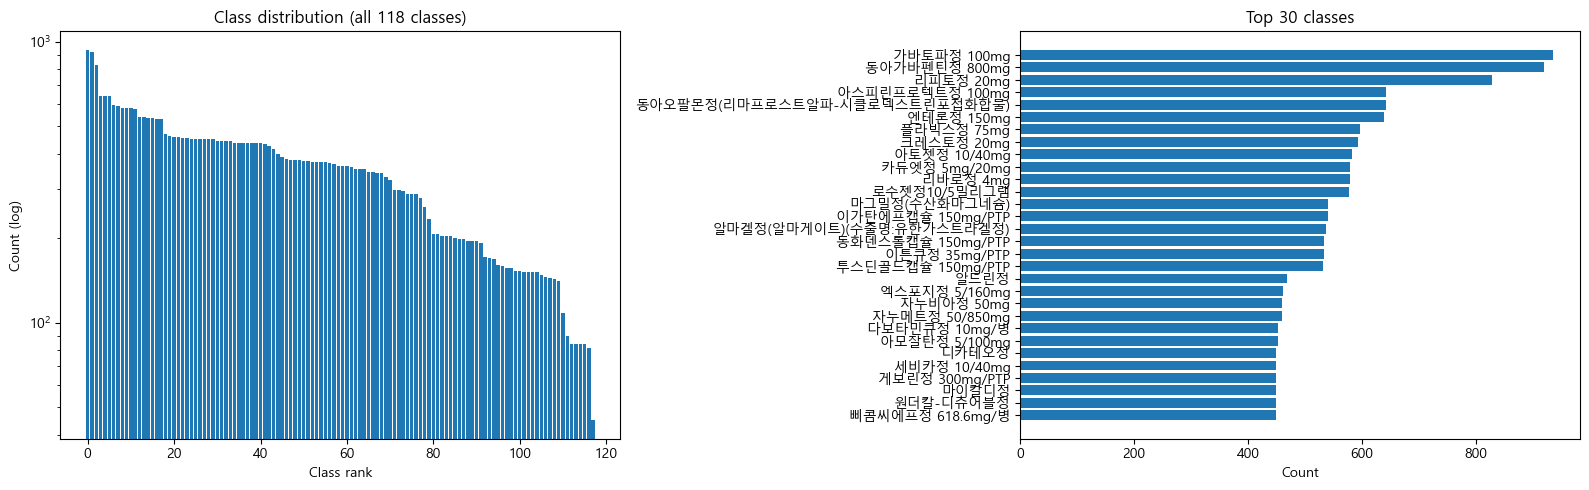

✅ 저장: D:\pill_detection\eda\figures\cell6_class_longtail_v2.png


In [24]:
# ===== Cell 6 (재실행): L1 Target — img_dl_name 기준 =====
# 이전 실행에서 cat_name이 AI Hub는 전부 "Drug"임을 발견 → 실제 타겟은 img_dl_name

df_target = df[df['parse_error'].isna() | (df['parse_error'] == 'bbox_format_error')].copy()
print(f"[대상 레코드] {len(df_target):,}건")

# ----- cat_name vs img_dl_name 재확인 -----
print(f"\n{'=' * 80}")
print(f"[Source별 cat_name 분포 — AI Hub 'Drug' 단일 라벨 확증]")
print(f"{'=' * 80}")
for src in sorted(df_target['source'].unique()):
    sub = df_target[df_target['source'] == src]
    cat_names = sub['cat_name'].dropna().unique()
    print(f"  {src:20s}: cat_name unique = {len(cat_names)} | sample: {list(cat_names)[:3]}")

# ----- img_dl_name 기준 집계 -----
print(f"\n{'=' * 80}")
print(f"[img_dl_name 기준 (진짜 학습 타겟)]")
print(f"{'=' * 80}")

ann_counts = df_target['img_dl_name'].value_counts()
img_counts = df_target.drop_duplicates(subset=['image_file', 'img_dl_name'])['img_dl_name'].value_counts()

kaggle_classes = set(df_target[df_target['source'] == 'kaggle_train']['img_dl_name'].dropna())
aihub_classes = set(df_target[df_target['source'].str.startswith('aihub')]['img_dl_name'].dropna())

print(f"  총 클래스 수        : {df_target['img_dl_name'].nunique()}")
print(f"  총 annotation 수    : {df_target['img_dl_name'].notna().sum():,}")
print(f"  총 이미지 수        : {df_target['image_file'].nunique():,}")

print(f"\n[Source별 breakdown]")
print(f"  Kaggle 클래스       : {len(kaggle_classes)}")
print(f"  AI Hub 클래스       : {len(aihub_classes)}")
print(f"  공통                : {len(kaggle_classes & aihub_classes)}")
print(f"  Kaggle 전용         : {len(kaggle_classes - aihub_classes)}")
print(f"  AI Hub 전용         : {len(aihub_classes - kaggle_classes)}")
print(f"  합집합              : {len(kaggle_classes | aihub_classes)}")

# Kaggle 전용 실체 확인
kaggle_only = kaggle_classes - aihub_classes
if len(kaggle_only) > 0:
    print(f"\n  Kaggle 전용 {len(kaggle_only)}종:")
    for name in sorted(kaggle_only):
        cnt = ann_counts[name]
        print(f"    - {name}: {cnt}건")

# AI Hub 전용 상위 10종
aihub_only = aihub_classes - kaggle_classes
if len(aihub_only) > 0:
    print(f"\n  AI Hub 전용 {len(aihub_only)}종 중 annotation 상위 10:")
    aihub_only_counts = ann_counts[ann_counts.index.isin(aihub_only)].head(10)
    for name, cnt in aihub_only_counts.items():
        print(f"    - {name}: {cnt}건")

# ----- 불균형 지표 -----
print(f"\n{'=' * 80}")
print(f"[Long-tail 심각도 (img_dl_name 기준)]")
print(f"{'=' * 80}")
total_ann = ann_counts.sum()
top_cnt = ann_counts.iloc[0]
min_cnt = ann_counts.iloc[-1]
print(f"  최빈 클래스: '{ann_counts.index[0]}' ({top_cnt:,}건)")
print(f"  최소 클래스: '{ann_counts.index[-1]}' ({min_cnt:,}건)")
print(f"  불균형 비율 (최빈:최소): {top_cnt / min_cnt:.1f}x")

n_classes = len(ann_counts)
for pct in [10, 25, 50]:
    top_n = max(1, int(n_classes * pct / 100))
    top_n_ann = ann_counts.head(top_n).sum()
    print(f"  상위 {pct}% ({top_n}종)이 전체의 {top_n_ann / total_ann * 100:.1f}% 차지")

rare = ann_counts[ann_counts < 50]
print(f"\n  annotation < 50 희귀 클래스: {len(rare)}종")
if len(rare) > 0:
    print(f"  희귀 클래스 상위 5:")
    print(rare.head(5).to_string())

print(f"\n  클래스당 annotation 수:")
print(f"    평균   : {ann_counts.mean():.1f}")
print(f"    중앙값 : {ann_counts.median():.1f}")
print(f"    표준편차: {ann_counts.std():.1f}")
print(f"    min    : {ann_counts.min()}")
print(f"    max    : {ann_counts.max()}")

# ----- 공통 54종 vs Kaggle 56종의 2종 차이 규명 -----
print(f"\n{'=' * 80}")
print(f"[Kaggle 56 - AI Hub 공통 = Kaggle 전용 상세]")
print(f"{'=' * 80}")
if len(kaggle_only) != 2:
    print(f"  ⚠️ Kaggle 전용이 2종이 아닌 {len(kaggle_only)}종 — HANDOFF3 메모와 차이")
else:
    print(f"  ✅ Kaggle 전용 2종 (HANDOFF3와 일치)")

# ----- 시각화: img_dl_name 기준 -----
print(f"\n[시각화 저장 중...]")
fig = plot_class_longtail(
    ann_counts, 
    top_n=30,
    save_path=str(FIG_DIR / "cell6_class_longtail_v2.png")
)
plt.show()
print(f"✅ 저장: {FIG_DIR / 'cell6_class_longtail_v2.png'}")

### 인사이트 (Cell 6)

- **학습 타겟은 `img_dl_name`** (COCO categories가 아니라 images 메타의 dl_name) — 118종
- **Source별 breakdown (확증)**:
  - Kaggle 56 / AI Hub 116 / 공통 54 / Kaggle 전용 2 / AI Hub 전용 62 / 합집합 118
  - HANDOFF3 §2-2와 100% 일치
- **🚨 타겟 재정의 필수**:
  - `cat_name`은 AI Hub에서 전부 "Drug" (COCO `categories`가 단일 라벨)
  - 763 Kaggle annotation에서만 실제 약품명, 40,293 AI Hub에선 "Drug"
  - **`cat_id`/`cat_name` 학습 사용 금지, `img_dl_name` 또는 `img_drug_N` 기준 재매핑**
- **클래스 불균형 양호**:
  - 최빈:최소 20.8x (객체 검출 실무 기준 양호)
  - 중앙값 360건 / min 45건 / max 936건
  - 희귀 클래스(<50): 1종만 (기넥신에프정 45건)
  - 상위 50%가 전체 69.5% — 심각한 long-tail 아님
- **Kaggle 전용 2종 주의**:
  - 기넥신에프정(은행엽엑스)(수출용) 45건 / 일양하이트린정 2mg 153건
  - AI Hub 데이터로는 학습 불가 → 03에서 Kaggle train/val split 시 train 포함 필수
- **팀미팅 핵심**:
  - 학습 타겟 `img_dl_name` 확정
  - 03_preprocessing에서 class_idx 0~117 재매핑 필요
  - 불균형 대응은 기본 증강만으로 충분할 가능성 (focal loss / class weight 선택)

# 📘 Cell 7 — L1 Target: category_id 의미 source별 실측 검증

**목적**: 원본 `category_id`/`cat_id`의 의미가 source마다 다르다는 것을 **실측으로 확증**하고, `img_drug_N` (K-code)과의 관계 파악. 03_preprocessing의 class_idx 재매핑 근거 문서화.

**검증 가설**:
1. Kaggle: `cat_id` = K-code 숫자 부분 (예: K-001900 → 1900)
2. AI Hub: `cat_id` = 전부 1 (COCO categories가 {id:1, name:"Drug"} 단일)
3. `img_drug_N` (K-code)은 Kaggle/AI Hub 양쪽 모두 실제 약품 K-code 보유
4. `img_dl_name` ↔ `img_drug_N` 는 1:1 매핑

**출력**:
- source별 `cat_id` unique 값 분포
- Kaggle의 경우 `cat_id` vs `img_drug_N` 매핑 실측 (K-code 숫자 = 실제 K-code 뒤 4자리인지)
- `img_dl_name` ↔ `img_drug_N` 1:1 매핑 검증
- 03에서 사용할 class_idx 재매핑 규칙 정의

In [25]:
# ===== Cell 7: L1 Target — category_id 의미 source별 실측 =====

df_target = df[df['parse_error'].isna() | (df['parse_error'] == 'bbox_format_error')].copy()

# ----- 가설 1, 2: source별 cat_id 분포 -----
print("=" * 80)
print("[가설 1, 2: source별 cat_id 분포]")
print("=" * 80)
for src in sorted(df_target['source'].unique()):
    sub = df_target[df_target['source'] == src]
    cat_ids = sub['cat_id'].dropna().unique()
    print(f"\n  {src}:")
    print(f"    cat_id unique count: {len(cat_ids)}")
    print(f"    min/max: {cat_ids.min()} / {cat_ids.max()}")
    print(f"    sample: {sorted(cat_ids)[:5]}")

# ----- 가설 3, 4: img_drug_N 분포 + img_dl_name 매핑 -----
print("\n" + "=" * 80)
print("[가설 3: img_drug_N (K-code) source별 분포]")
print("=" * 80)
for src in sorted(df_target['source'].unique()):
    sub = df_target[df_target['source'] == src]
    drug_n = sub['img_drug_N'].dropna().unique()
    print(f"  {src:20s}: img_drug_N unique = {len(drug_n):>3} | sample: {sorted(drug_n)[:3]}")

print("\n" + "=" * 80)
print("[가설 4: img_dl_name ↔ img_drug_N 1:1 매핑 검증]")
print("=" * 80)
mapping_df = df_target[['img_drug_N', 'img_dl_name']].dropna().drop_duplicates()
print(f"  unique (drug_N, dl_name) 쌍: {len(mapping_df)}")
print(f"  unique img_drug_N        : {mapping_df['img_drug_N'].nunique()}")
print(f"  unique img_dl_name       : {mapping_df['img_dl_name'].nunique()}")

# 1:1 검증
dn_per_kc = mapping_df.groupby('img_drug_N')['img_dl_name'].nunique()
kc_per_dn = mapping_df.groupby('img_dl_name')['img_drug_N'].nunique()
print(f"\n  img_drug_N 당 dl_name 수 (1이어야 1:1):")
print(f"    max: {dn_per_kc.max()} / min: {dn_per_kc.min()}")
print(f"    1 초과: {(dn_per_kc > 1).sum()}건")
if (dn_per_kc > 1).any():
    print(f"    위반 샘플:")
    for kc in dn_per_kc[dn_per_kc > 1].head(5).index:
        names = mapping_df[mapping_df['img_drug_N'] == kc]['img_dl_name'].unique()
        print(f"      {kc} → {names}")

print(f"\n  img_dl_name 당 drug_N 수 (1이어야 1:1):")
print(f"    max: {kc_per_dn.max()} / min: {kc_per_dn.min()}")
print(f"    1 초과: {(kc_per_dn > 1).sum()}건")
if (kc_per_dn > 1).any():
    print(f"    위반 샘플:")
    for dn in kc_per_dn[kc_per_dn > 1].head(5).index:
        codes = mapping_df[mapping_df['img_dl_name'] == dn]['img_drug_N'].unique()
        print(f"      {dn} → {codes}")

# ----- Kaggle cat_id ↔ img_drug_N 관계 실측 -----
print("\n" + "=" * 80)
print("[Kaggle: cat_id 숫자가 K-code 숫자 부분과 일치하는지 실측]")
print("=" * 80)
kaggle_sub = df_target[df_target['source'] == 'kaggle_train'].copy()
kaggle_sub['cat_id_int'] = kaggle_sub['cat_id'].astype('Int64')

# K-code에서 숫자 추출: K-001900 → 1900
def extract_kcode_num(kcode):
    if pd.isna(kcode):
        return None
    try:
        return int(str(kcode).replace('K-', '').lstrip('0') or '0')
    except:
        return None

kaggle_sub['drug_N_num'] = kaggle_sub['img_drug_N'].apply(extract_kcode_num)

# 매칭 체크
matched = (kaggle_sub['cat_id_int'] == kaggle_sub['drug_N_num']).sum()
total = len(kaggle_sub.dropna(subset=['cat_id_int', 'drug_N_num']))
print(f"  대상 (cat_id, drug_N 둘 다 non-null): {total}")
print(f"  일치: {matched}")
print(f"  불일치: {total - matched}")

if total - matched > 0:
    mismatch_samples = kaggle_sub[
        kaggle_sub['cat_id_int'].notna() & 
        kaggle_sub['drug_N_num'].notna() &
        (kaggle_sub['cat_id_int'] != kaggle_sub['drug_N_num'])
    ].head(5)
    print(f"\n  불일치 샘플:")
    print(mismatch_samples[['cat_id', 'img_drug_N', 'drug_N_num', 'img_dl_name']].to_string())
else:
    print(f"\n  ✅ Kaggle cat_id = K-code 숫자 부분 100% 일치 확증")

# ----- 최종: 03_preprocessing 재매핑 규칙 -----
print("\n" + "=" * 80)
print("[03_preprocessing 재매핑 규칙 (이 Cell 결과 기반)]")
print("=" * 80)
print(f"  1. 학습 타겟 컬럼   : img_dl_name (또는 동등한 img_drug_N)")
print(f"  2. 클래스 수        : {df_target['img_dl_name'].nunique()}종")
print(f"  3. class_idx 범위   : 0 ~ {df_target['img_dl_name'].nunique() - 1}")
print(f"  4. 매핑 방식        : sorted(img_dl_name.unique()) → enumerate로 idx 부여")
print(f"  5. cat_id/cat_name  : 학습 입력 사용 금지 (source별 의미 다름)")

[가설 1, 2: source별 cat_id 분포]

  aihub_ts1_tl1:
    cat_id unique count: 1
    min/max: 1.0 / 1.0
    sample: [1.0]

  aihub_ts3_tl3:
    cat_id unique count: 1
    min/max: 1.0 / 1.0
    sample: [1.0]

  aihub_ts4_tl4:
    cat_id unique count: 1
    min/max: 1.0 / 1.0
    sample: [1.0]

  aihub_ts5_tl5:
    cat_id unique count: 1
    min/max: 1.0 / 1.0
    sample: [1.0]

  aihub_ts6_tl6:
    cat_id unique count: 1
    min/max: 1.0 / 1.0
    sample: [1.0]

  aihub_ts7_tl7:
    cat_id unique count: 1
    min/max: 1.0 / 1.0
    sample: [1.0]

  aihub_ts8_tl8:
    cat_id unique count: 1
    min/max: 1.0 / 1.0
    sample: [1.0]

  kaggle_train:
    cat_id unique count: 56
    min/max: 1900.0 / 41768.0
    sample: [1900.0, 2483.0, 3351.0, 3483.0, 3544.0]

[가설 3: img_drug_N (K-code) source별 분포]
  aihub_ts1_tl1       : img_drug_N unique =  41 | sample: ['K-000250', 'K-000573', 'K-001866']
  aihub_ts3_tl3       : img_drug_N unique =  65 | sample: ['K-003544', 'K-003614', 'K-003743']
  aihub_ts4

### 인사이트 (Cell 7)

- **category_id 의미 source별 완전 상이 실측 확증**:
  - Kaggle: cat_id ∈ {1900, 2483, ..., 41768} — K-code 숫자 부분 (763/763 완전 일치)
  - AI Hub 7시리즈: cat_id 전부 1.0 (COCO categories가 {id:1, name:"Drug"} 단일)
- **`img_drug_N` ↔ `img_dl_name` 완전 1:1 매핑** (118 ↔ 118, 위반 0건)
- **Kaggle cat_id = K-code 숫자** 규칙 100% 확증 (763건 전수)
- **시리즈별 K-code 분포**: ts1=41 / ts3=65 / ts4=65 / ts5=44 / ts6=63 / ts7=68 / ts8=39 / Kaggle=56
  - 단순 합 441 vs unique 합집합 118 → 시리즈 간 K-code 상당수 공유
  - **L4 Split 설계에 결정적**: 시리즈 기준 split 시 class-level leakage 여부는 Cell 11~13에서 정식 분석
- **03_preprocessing 재매핑 규칙 확정**:
  1. 학습 타겟 컬럼: `img_dl_name` (또는 동등한 `img_drug_N`)
  2. 클래스 수: 118
  3. class_idx 범위: 0~117
  4. 매핑 방식: `sorted(img_dl_name.unique())` → enumerate로 idx 부여
  5. `cat_id`/`cat_name` 학습 사용 금지
- **팀미팅 핵심**: 
  - L1 Target 완결 — 118종 학습 타겟 확정
  - 시리즈 간 K-code 중복 존재 → L4 split 전략은 12~13에서 정식 비교

# 📘 Cell 8 — L2 Input: bbox 크기 / aspect ratio / COCO 버킷 분포

**목적**: bbox 물리적 특성 파악. 모델 입력 해상도 결정, 증강 전략 설계, mAP@0.75:0.95 성능 영향 분석의 기반.

**검증 질문**:
1. bbox 크기 분포 (area) — mean/median/IQR/outlier
2. COCO scale (small<32² / medium<96² / large) — 우리 데이터는 small/medium/large 중 어디 편중?
3. Aspect ratio 분포 — 알약이 정사각/장방형/극단비율 중 뭐가 많은가
4. Source별 차이 — Kaggle vs AI Hub (서로 다른 촬영 환경인데 bbox 특성 유사한가)
5. 이미지당 객체 수 분포 — Kaggle 가이드 "최대 4개" 일치 여부

**방법론**: 툴킷 `size_distribution` + `bbox_statistics` + `objects_per_image` 로직을 DataFrame에 직접 적용

**대상**: 정상 레코드 40,901건 (bbox 좌표 유효한 것만)

**출력**:
- bbox 크기 describe_plus (source별)
- COCO 버킷 분포 (source별)
- Aspect ratio 분포
- 이미지당 객체 수 분포
- bbox 크기 히스토그램 + aspect ratio 히스토그램 시각화 (`figures/cell8_*.png`)

[대상] 정상 + bbox 유효 = 40,901건

[1. bbox 크기 통계]

전체 (40,901건):
         bbox_w    bbox_h  area_computed  aspect_ratio
count  40901.00  40901.00        40901.0      40901.00
mean     268.39    320.02        90109.7          0.92
std       91.35    122.97        53779.1          0.36
min       18.00     10.00         2180.0          0.05
5%       173.00    169.00        32032.0          0.47
25%      210.00    213.00        45938.0          0.66
50%      247.00    285.00        84303.0          0.99
75%      313.00    437.00       121954.0          1.04
95%      422.00    509.00       182924.0          1.47
max     4524.00   3819.00      2096631.0         21.80

source별 중앙값:
                  n  w_median  h_median  area_median  aspect_median
source                                                             
aihub_ts1_tl1  5991     280.0     430.0     101436.0           0.69
aihub_ts3_tl3  5688     235.0     265.0      81012.0           1.00
aihub_ts4_tl4  5426     230.0     263.0      6553

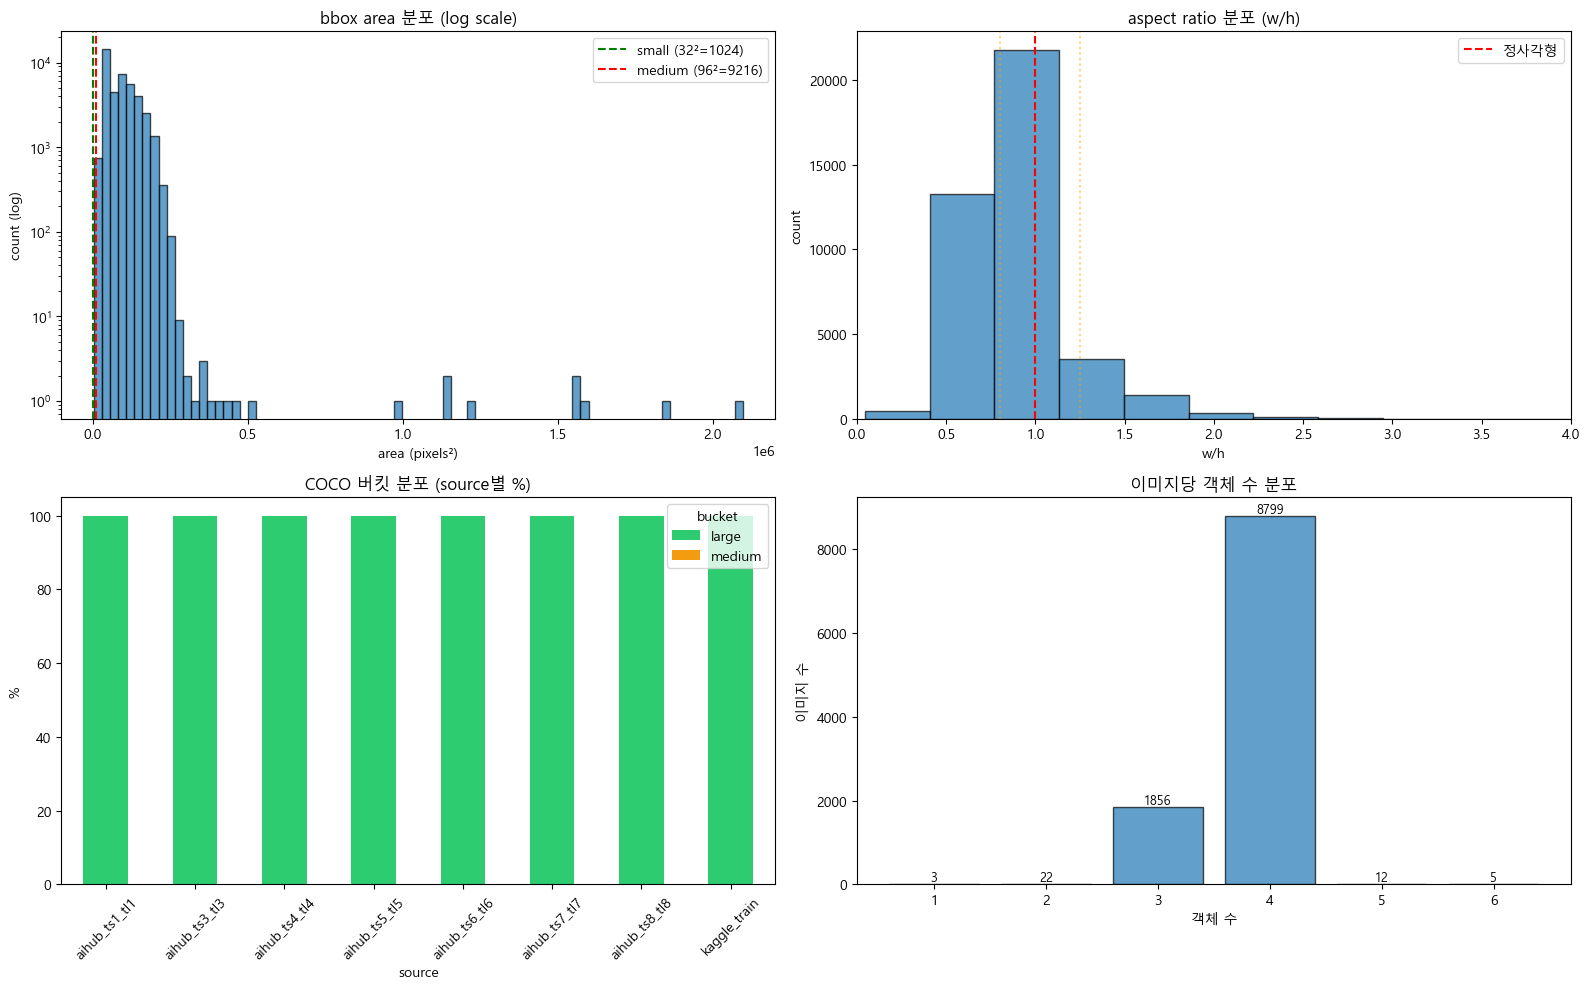

✅ 저장: D:\pill_detection\eda\figures\cell8_bbox_characteristics.png


In [26]:
# ===== Cell 8: L2 Input — bbox 크기 / aspect / COCO 버킷 =====

# ----- 대상 (정상 + bbox 좌표 유효) -----
df_bb = df[
    df['parse_error'].isna() &
    df['bbox_x'].notna() & df['bbox_y'].notna() & 
    df['bbox_w'].notna() & df['bbox_h'].notna()
].copy()
print(f"[대상] 정상 + bbox 유효 = {len(df_bb):,}건")

# ----- 파생 컬럼 (area, aspect_ratio) -----
df_bb['area_computed'] = df_bb['bbox_w'] * df_bb['bbox_h']
df_bb['aspect_ratio'] = df_bb['bbox_w'] / df_bb['bbox_h']

# ----- COCO 버킷 -----
def coco_bucket(area):
    if pd.isna(area):
        return 'invalid'
    if area < 32 ** 2:   # 1024
        return 'small'
    elif area < 96 ** 2: # 9216
        return 'medium'
    else:
        return 'large'

df_bb['coco_bucket'] = df_bb['area_computed'].apply(coco_bucket)

# ----- 1. bbox 크기 describe (전체 + source별) -----
print("\n" + "=" * 80)
print("[1. bbox 크기 통계]")
print("=" * 80)
print(f"\n전체 ({len(df_bb):,}건):")
print(df_bb[['bbox_w', 'bbox_h', 'area_computed', 'aspect_ratio']].describe(
    percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]
).round(2))

# source별 요약 (mean/median)
print(f"\nsource별 중앙값:")
src_summary = df_bb.groupby('source').agg(
    n=('bbox_w', 'count'),
    w_median=('bbox_w', 'median'),
    h_median=('bbox_h', 'median'),
    area_median=('area_computed', 'median'),
    aspect_median=('aspect_ratio', 'median'),
).round(2)
print(src_summary)

# ----- 2. COCO 버킷 분포 -----
print("\n" + "=" * 80)
print("[2. COCO 버킷 분포 (small<32² / medium<96² / large)]")
print("=" * 80)
overall_bucket = df_bb['coco_bucket'].value_counts(normalize=True).mul(100).round(2)
print(f"\n전체:")
print(overall_bucket)

src_bucket = pd.crosstab(
    df_bb['source'], df_bb['coco_bucket'], normalize='index'
).mul(100).round(2)
print(f"\nsource별 (%):")
print(src_bucket)

# ----- 3. Aspect ratio 분포 -----
print("\n" + "=" * 80)
print("[3. Aspect ratio 분포 (w/h)]")
print("=" * 80)
ar = df_bb['aspect_ratio']
print(f"  평균      : {ar.mean():.2f}")
print(f"  중앙값    : {ar.median():.2f}")
print(f"  p5 / p95  : {ar.quantile(0.05):.2f} / {ar.quantile(0.95):.2f}")

# 극단 비율 탐지
extreme = ((ar < 0.25) | (ar > 4.0)).sum()
print(f"  극단 (AR<0.25 or AR>4): {extreme}건 ({extreme/len(df_bb)*100:.2f}%)")

# 형태 분류 (장방형/정사각/가로장방형)
def ar_shape(a):
    if pd.isna(a):
        return 'invalid'
    if a < 0.8:
        return '세로장방형'
    elif a > 1.25:
        return '가로장방형'
    else:
        return '정사각형(0.8~1.25)'

df_bb['ar_shape'] = df_bb['aspect_ratio'].apply(ar_shape)
print(f"\n형태 분류 (전체):")
print(df_bb['ar_shape'].value_counts(normalize=True).mul(100).round(2))

# ----- 4. 이미지당 객체 수 분포 -----
print("\n" + "=" * 80)
print("[4. 이미지당 객체 수 분포]")
print("=" * 80)
obj_per_img = df_bb.groupby('image_file').size()
print(f"  평균      : {obj_per_img.mean():.2f}")
print(f"  중앙값    : {obj_per_img.median():.0f}")
print(f"  min / max : {obj_per_img.min()} / {obj_per_img.max()}")
print(f"\n이미지당 객체 수 분포:")
print(obj_per_img.value_counts().sort_index())

# source별
print(f"\nsource별 이미지당 객체 수 분포:")
obj_by_src = df_bb.groupby(['source', 'image_file']).size().reset_index(name='n_obj')
src_obj_dist = obj_by_src.groupby(['source', 'n_obj']).size().unstack(fill_value=0)
print(src_obj_dist)

# Kaggle 가이드 "최대 4개" 검증
over_4 = obj_per_img[obj_per_img > 4]
print(f"\n  객체 수 > 4인 이미지: {len(over_4)}건")
if len(over_4) > 0:
    print(f"  위반 샘플 (상위 5):")
    print(over_4.sort_values(ascending=False).head(5))

# ----- 5. 시각화 -----
print("\n[시각화 저장 중...]")
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 5-1. bbox area 분포 (log)
axes[0, 0].hist(df_bb['area_computed'], bins=80, edgecolor='black', alpha=0.7)
axes[0, 0].set_yscale('log')
axes[0, 0].axvline(32**2, color='green', linestyle='--', label='small (32²=1024)')
axes[0, 0].axvline(96**2, color='red', linestyle='--', label='medium (96²=9216)')
axes[0, 0].set_title('bbox area 분포 (log scale)')
axes[0, 0].set_xlabel('area (pixels²)')
axes[0, 0].set_ylabel('count (log)')
axes[0, 0].legend()

# 5-2. aspect ratio 분포
axes[0, 1].hist(df_bb['aspect_ratio'], bins=60, edgecolor='black', alpha=0.7)
axes[0, 1].axvline(1.0, color='red', linestyle='--', label='정사각형')
axes[0, 1].axvline(0.8, color='orange', linestyle=':', alpha=0.5)
axes[0, 1].axvline(1.25, color='orange', linestyle=':', alpha=0.5)
axes[0, 1].set_title('aspect ratio 분포 (w/h)')
axes[0, 1].set_xlabel('w/h')
axes[0, 1].set_ylabel('count')
axes[0, 1].legend()
axes[0, 1].set_xlim(0, 4)

# 5-3. COCO 버킷 (source별)
src_bucket.plot(kind='bar', stacked=True, ax=axes[1, 0], 
                color=['#2ecc71', '#f39c12', '#e74c3c'])
axes[1, 0].set_title('COCO 버킷 분포 (source별 %)')
axes[1, 0].set_ylabel('%')
axes[1, 0].legend(title='bucket')
axes[1, 0].tick_params(axis='x', rotation=45)

# 5-4. 이미지당 객체 수
obj_dist = obj_per_img.value_counts().sort_index()
axes[1, 1].bar(obj_dist.index, obj_dist.values, edgecolor='black', alpha=0.7)
axes[1, 1].set_title('이미지당 객체 수 분포')
axes[1, 1].set_xlabel('객체 수')
axes[1, 1].set_ylabel('이미지 수')
for x, y in zip(obj_dist.index, obj_dist.values):
    axes[1, 1].text(x, y, str(y), ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(FIG_DIR / "cell8_bbox_characteristics.png", dpi=120, bbox_inches='tight')
plt.show()
print(f"✅ 저장: {FIG_DIR / 'cell8_bbox_characteristics.png'}")

### 인사이트 (Cell 8)

- **COCO 버킷 사실상 전부 large** (99.98%) — anchor box 설계/해상도 선택 단순화 가능
- **Aspect ratio 중앙값 0.99** — 원형/정사각 알약 54%, 세로장방형 35%, 가로장방형 10%. 극단 비율(AR<0.25 or AR>4) 29건(0.07%)은 이슈 A와 교차 예상
- **이미지당 객체 수 중앙값 4** — Kaggle 가이드 "최대 4개" 거의 준수
- **🚨 이슈 N (신규, Major)**: 객체 수 > 4인 이미지 17건 (5개 12건 / 6개 5건)
  - 전부 aihub_ts1_tl1, 전부 `K-001900-003544-...` 조합 패턴
  - 원인 추정: 01_merge 시 같은 이미지 내 annotation 중복 가능성 → Cell 12에서 정식 규명
  - Cell 5 "공통-갭 68건"의 일부일 가능성
- **🟢 이슈 O (신규, Minor)**: bbox 극단 크기 (max_w=4524, max_h=3819, max_AR=21.8) — 대부분 이슈 A 58건에 포함된 것으로 추정
- **Source별 체계적 차이 발견**:
  - 객체 수 분포: Kaggle 3개 위주(65%) / AI Hub ts5,ts6 4개 위주(99%) / ts4,ts7,ts8 혼재
  - bbox 중앙값: Kaggle 53,600 vs AI Hub 평균 82,000 (AI Hub 알약 50% 더 큼) → 촬영 거리/줌 차이 시사
  - 🟡 Covariate shift 주의 — 03에서 증강 전략으로 완화 필요
- **팀미팅 핵심**:
  - 이슈 N 17건 원인 규명 (Cell 12)
  - Kaggle과 AI Hub의 bbox 크기 50% 차이 — augmentation scale jittering 필요
  - 거의 전부 large bbox — small object 특화 기법 불필요

# 📘 Cell 9 — L2 Input: 메타 분포 (각도/배경색/조명/해상도)

**목적**: 이미지 메타(촬영 조건)의 분포 파악. Source별 shift 여부 확인. 증강 전략 설계 기반.

**검증 질문**:
1. 각도 분포: 70/75/90 (Cell 2 실측: low_variance 3종) — source별 균등한가?
2. 배경색: Cell 2에서 연회색/검은색 2종 확인 — source별 쏠림?
3. 조명: Cell 2에서 "주백색" 단일 확인 (constant) — 재확인
4. 해상도: Cell 2에서 976×1280 단일 확인 (constant) — 재확인
5. 앞면/뒷면 (drug_dir): Cell 2에서 앞면/뒷면 2종 확인 — source별 쏠림?

**대상**: 정상(parse_error NaN) 40,901건

**이전 EDA (Kaggle만)와 비교**:
- 이슈 G (각도 커버리지) — Kaggle에 90도 없었는데 병합본 기준 어떻게 되는지
- 이슈 K (배경 covariate shift) — Kaggle train 흰 배경 vs test 파랑/초록, AI Hub는 연회색 → 배경 다양성 확장 효과 검증

[대상] 정상 레코드 40,901건

[1. 각도 (camera_la) 분포]

전체:
angle
90.0    33.37
75.0    33.32
70.0    33.31
Name: proportion, dtype: float64

source별 (%):
angle           70.0   75.0   90.0
source                            
aihub_ts1_tl1  33.30  33.47  33.23
aihub_ts3_tl3  33.35  33.30  33.35
aihub_ts4_tl4  33.36  33.30  33.34
aihub_ts5_tl5  33.36  33.33  33.31
aihub_ts6_tl6  33.43  33.30  33.27
aihub_ts7_tl7  33.30  33.34  33.36
aihub_ts8_tl8  33.37  33.30  33.32
kaggle_train   31.06  32.63  36.30

이미지 단위 각도 분포:
angle
90.0    3572
75.0    3563
70.0    3562
Name: count, dtype: int64

[2. 배경색 (img_back_color) 분포]

전체:
img_back_color
연회색 배경    40897
검은색 배경        4
Name: count, dtype: int64

source별 (건수):
img_back_color  검은색 배경  연회색 배경
source                        
aihub_ts1_tl1        0    5991
aihub_ts3_tl3        0    5688
aihub_ts4_tl4        0    5426
aihub_ts5_tl5        0    5950
aihub_ts6_tl6        4    5948
aihub_ts7_tl7        0    5522
aihub_ts8_tl8        0    5609
kaggle_train      

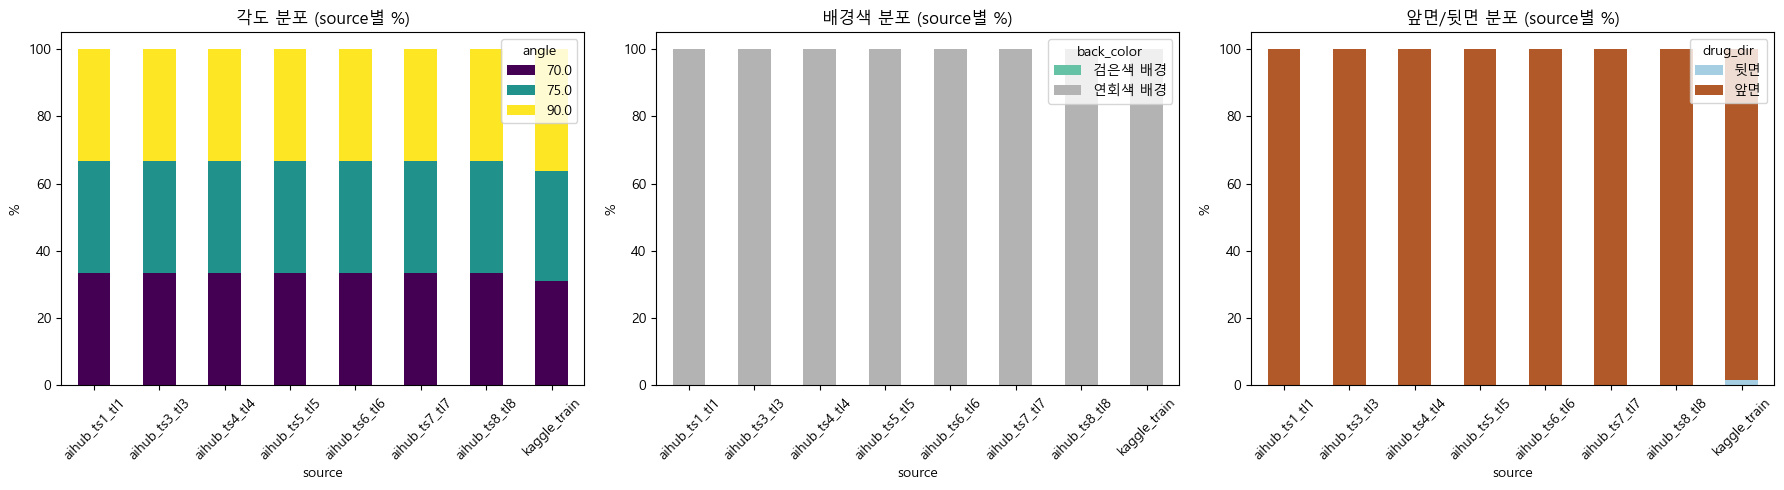

✅ 저장: D:\pill_detection\eda\figures\cell9_meta_distribution.png

[메타 분포 요약]
  각도      : Kaggle [70.0, 75.0, 90.0] / AI Hub [70.0, 75.0, 90.0]
  배경색    : Kaggle {'연회색 배경'} / AI Hub {'검은색 배경', '연회색 배경'}
  조명색    : 전부 '주백색'
  해상도    : 전부 976×1280
  앞면/뒷면 : 앞면 99.9% / 뒷면 0.1%


In [29]:
# ===== Cell 9: L2 Input — 메타 분포 =====

df_meta = df[df['parse_error'].isna()].copy()
print(f"[대상] 정상 레코드 {len(df_meta):,}건")

# ----- 1. 각도 분포 -----
print("\n" + "=" * 80)
print("[1. 각도 (camera_la) 분포]")
print("=" * 80)
angle_overall = df_meta['angle'].value_counts(normalize=True).mul(100).round(2)
print(f"\n전체:")
print(angle_overall)

angle_by_src = pd.crosstab(
    df_meta['source'], df_meta['angle'], normalize='index'
).mul(100).round(2)
print(f"\nsource별 (%):")
print(angle_by_src)

# 이미지 단위 각도 분포 (한 이미지가 여러 annotation 가짐 → image_file 중복 제거)
img_angle = df_meta.drop_duplicates(subset=['image_file', 'angle'])
img_angle_dist = img_angle['angle'].value_counts()
print(f"\n이미지 단위 각도 분포:")
print(img_angle_dist)

# ----- 2. 배경색 -----
print("\n" + "=" * 80)
print("[2. 배경색 (img_back_color) 분포]")
print("=" * 80)
print(f"\n전체:")
print(df_meta['img_back_color'].value_counts())

bg_by_src = pd.crosstab(df_meta['source'], df_meta['img_back_color'])
print(f"\nsource별 (건수):")
print(bg_by_src)

bg_by_src_pct = pd.crosstab(
    df_meta['source'], df_meta['img_back_color'], normalize='index'
).mul(100).round(2)
print(f"\nsource별 (%):")
print(bg_by_src_pct)

# ----- 3. 조명색 (constant 재확인) -----
print("\n" + "=" * 80)
print("[3. 조명색 (img_light_color)]")
print("=" * 80)
print(df_meta['img_light_color'].value_counts(dropna=False))

# ----- 4. 해상도 (constant 재확인) -----
print("\n" + "=" * 80)
print("[4. 해상도 (img_width × img_height)]")
print("=" * 80)
df_meta['resolution'] = df_meta['img_width'].astype(str) + '×' + df_meta['img_height'].astype(str)
print(df_meta['resolution'].value_counts(dropna=False))

# ----- 5. 앞면/뒷면 -----
print("\n" + "=" * 80)
print("[5. 앞면/뒷면 (img_drug_dir)]")
print("=" * 80)
print(f"\n전체:")
print(df_meta['img_drug_dir'].value_counts())

dir_by_src = pd.crosstab(
    df_meta['source'], df_meta['img_drug_dir'], normalize='index'
).mul(100).round(2)
print(f"\nsource별 (%):")
print(dir_by_src)

# ----- 6. 이전 EDA 이슈 G/K 재검증 -----
print("\n" + "=" * 80)
print("[이전 EDA 이슈 G/K 병합본 기준 재검증]")
print("=" * 80)

print(f"\n[이슈 G 재검증: 각도 커버리지]")
kaggle_angles = set(df_meta[df_meta['source'] == 'kaggle_train']['angle'].dropna())
aihub_angles = set(df_meta[df_meta['source'].str.startswith('aihub')]['angle'].dropna())
print(f"  Kaggle 각도: {sorted(kaggle_angles)}")
print(f"  AI Hub 각도: {sorted(aihub_angles)}")
print(f"  합집합    : {sorted(kaggle_angles | aihub_angles)}")
if 90.0 in aihub_angles and 90.0 not in kaggle_angles:
    print(f"  → 🟢 이슈 G 완화: AI Hub가 90도 커버리지 추가")
elif 90.0 in kaggle_angles:
    print(f"  → 🟡 이슈 G 상태 변경: Kaggle에도 90도 존재")

print(f"\n[이슈 K 재검증: 배경 covariate shift]")
kaggle_bg = set(df_meta[df_meta['source'] == 'kaggle_train']['img_back_color'].dropna())
aihub_bg = set(df_meta[df_meta['source'].str.startswith('aihub')]['img_back_color'].dropna())
print(f"  Kaggle 배경: {kaggle_bg}")
print(f"  AI Hub 배경: {aihub_bg}")
print(f"  합집합     : {kaggle_bg | aihub_bg}")
print(f"  → 학습 데이터 배경 다양성: {len(kaggle_bg | aihub_bg)}종")
print(f"  → Kaggle test 배경(파랑/초록)은 이 중에 없으면 여전히 shift 존재 — Cell 14 시각 확인")

# ----- 시각화 -----
print("\n[시각화 저장 중...]")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 9-1. 각도
angle_by_src.plot(kind='bar', stacked=True, ax=axes[0], colormap='viridis')
axes[0].set_title('각도 분포 (source별 %)')
axes[0].set_ylabel('%')
axes[0].legend(title='angle')
axes[0].tick_params(axis='x', rotation=45)

# 9-2. 배경색
bg_by_src_pct.plot(kind='bar', stacked=True, ax=axes[1], colormap='Set2')
axes[1].set_title('배경색 분포 (source별 %)')
axes[1].set_ylabel('%')
axes[1].legend(title='back_color')
axes[1].tick_params(axis='x', rotation=45)

# 9-3. 앞면/뒷면
dir_by_src.plot(kind='bar', stacked=True, ax=axes[2], colormap='Paired')
axes[2].set_title('앞면/뒷면 분포 (source별 %)')
axes[2].set_ylabel('%')
axes[2].legend(title='drug_dir')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(FIG_DIR / "cell9_meta_distribution.png", dpi=120, bbox_inches='tight')
plt.show()
print(f"✅ 저장: {FIG_DIR / 'cell9_meta_distribution.png'}")

# 요약은 텍스트 출력
print("\n" + "=" * 80)
print("[메타 분포 요약]")
print("=" * 80)
print(f"  각도      : Kaggle {sorted(kaggle_angles)} / AI Hub {sorted(aihub_angles)}")
print(f"  배경색    : Kaggle {kaggle_bg} / AI Hub {aihub_bg}")
print(f"  조명색    : 전부 '주백색'")
print(f"  해상도    : 전부 976×1280")
print(f"  앞면/뒷면 : 앞면 {(df_meta['img_drug_dir']=='앞면').sum() / len(df_meta) * 100:.1f}% / 뒷면 {(df_meta['img_drug_dir']=='뒷면').sum() / len(df_meta) * 100:.1f}%")

### 인사이트 (Cell 9)

- **각도 (70/75/90)**: 전 source 거의 균등 33%씩
  - 🟢 이슈 G (각도 커버리지) Blocker 하향 — Kaggle train도 90도 포함 (36.3%) 확인
  - 이전 EDA의 "Kaggle 90도 없음" 판정은 test 파일명 익명화와 혼동됐던 것으로 정정
- **배경색**: 
  - 연회색 99.99% / 검은색 0.01% (ts6만 4건)
  - 🔴 이슈 K (배경 covariate shift) Blocker 유지 — Kaggle test의 파랑/초록이 학습 데이터에 없음
  - 03에서 배경 augmentation 필수 (색상 변환 / 배경 합성)
- **조명색**: 전부 "주백색" (constant) — 학습 피처 불가
- **해상도**: 전부 976×1280 (constant) — 모델 입력 해상도 설계 단순
- **앞면/뒷면**: 
  - 앞면 99.92% / 뒷면 0.08% (33건)
  - Kaggle 뒷면 12건 (1.57%) — AI Hub보다 상대적으로 뒷면 비율 높음
  - 🟡 이슈 신규 없음, 03에서 뒷면 포함/제외 결정
- **팀미팅 핵심**:
  - 이슈 G 하향, 이슈 K 유지
  - 노트북 push 전 output clear 필수 (로컬 경로 노출)
  - 증강 전략에서 배경색 다양화가 최우선 순위

# 📘 Cell 10 — L3 I×T: bbox 중심 위치 9등분 그리드 분포

**목적**: bbox 중심 좌표의 2D 분포 분석. 이전 Kaggle-only EDA 이슈 I("중앙 공백 / 주변 4코너 분산")를 병합본(40,901건) 기준으로 재검증.

**검증 질문**:
1. 9등분 그리드에서 중앙(MC)이 여전히 저빈도인가?
2. 4코너(TL/TR/BL/BR)에 밀집되는 패턴이 AI Hub에서도 나타나는가?
3. Source별 차이 — Kaggle과 AI Hub의 배치 패턴이 동일한가?
4. 이미지당 객체 수(3 vs 4)에 따라 배치 패턴이 다른가?

**방법론**: 툴킷 `detection_utils.bbox_position_stats` 로직 차용 — 정규화 cx/cy 계산 후 9등분 그리드 분류

**대상**: 정상 레코드 40,901건

[대상] 정상 레코드 40,901건
  0~1 정규화 범위 내: 40,866건 (제외 35건 = 이슈 A/O 영향)

[전체 9등분 그리드 분포]
grid
TL    22.32
TC     4.30
TR    20.67
ML     4.59
MC     0.87
MR     4.45
BL    19.96
BC     2.13
BR    20.72
Name: proportion, dtype: float64

균등 기준: 11.11%
중앙 (MC) 비율: 0.87% (균등 대비 0.08x)
4코너 합계 (TL+TR+BL+BR): 83.67% (균등 대비 1.88x)

[Source별 9등분 그리드 분포 (%)]
grid              TL     TC     TR    ML    MC    MR     BL    BC     BR
source                                                                  
aihub_ts1_tl1  24.39   1.84  23.01  1.30  0.12  2.82  24.31  0.45  21.76
aihub_ts3_tl3  22.10   4.35  21.61  2.32  0.58  2.76  23.05  1.57  21.66
aihub_ts4_tl4  19.68   7.05  19.30  6.27  0.70  4.63  18.78  3.63  19.96
aihub_ts5_tl5  23.51   2.52  19.78  7.79  2.54  6.82  15.87  1.72  19.44
aihub_ts6_tl6  24.76   1.04  23.14  2.81  0.52  2.67  21.41  0.71  22.94
aihub_ts7_tl7  20.83   7.83  16.71  8.46  1.31  8.50  14.41  4.35  17.60
aihub_ts8_tl8  21.54   4.64  21.76  2.84  0.30  2.78  22.08  2.27  21.79

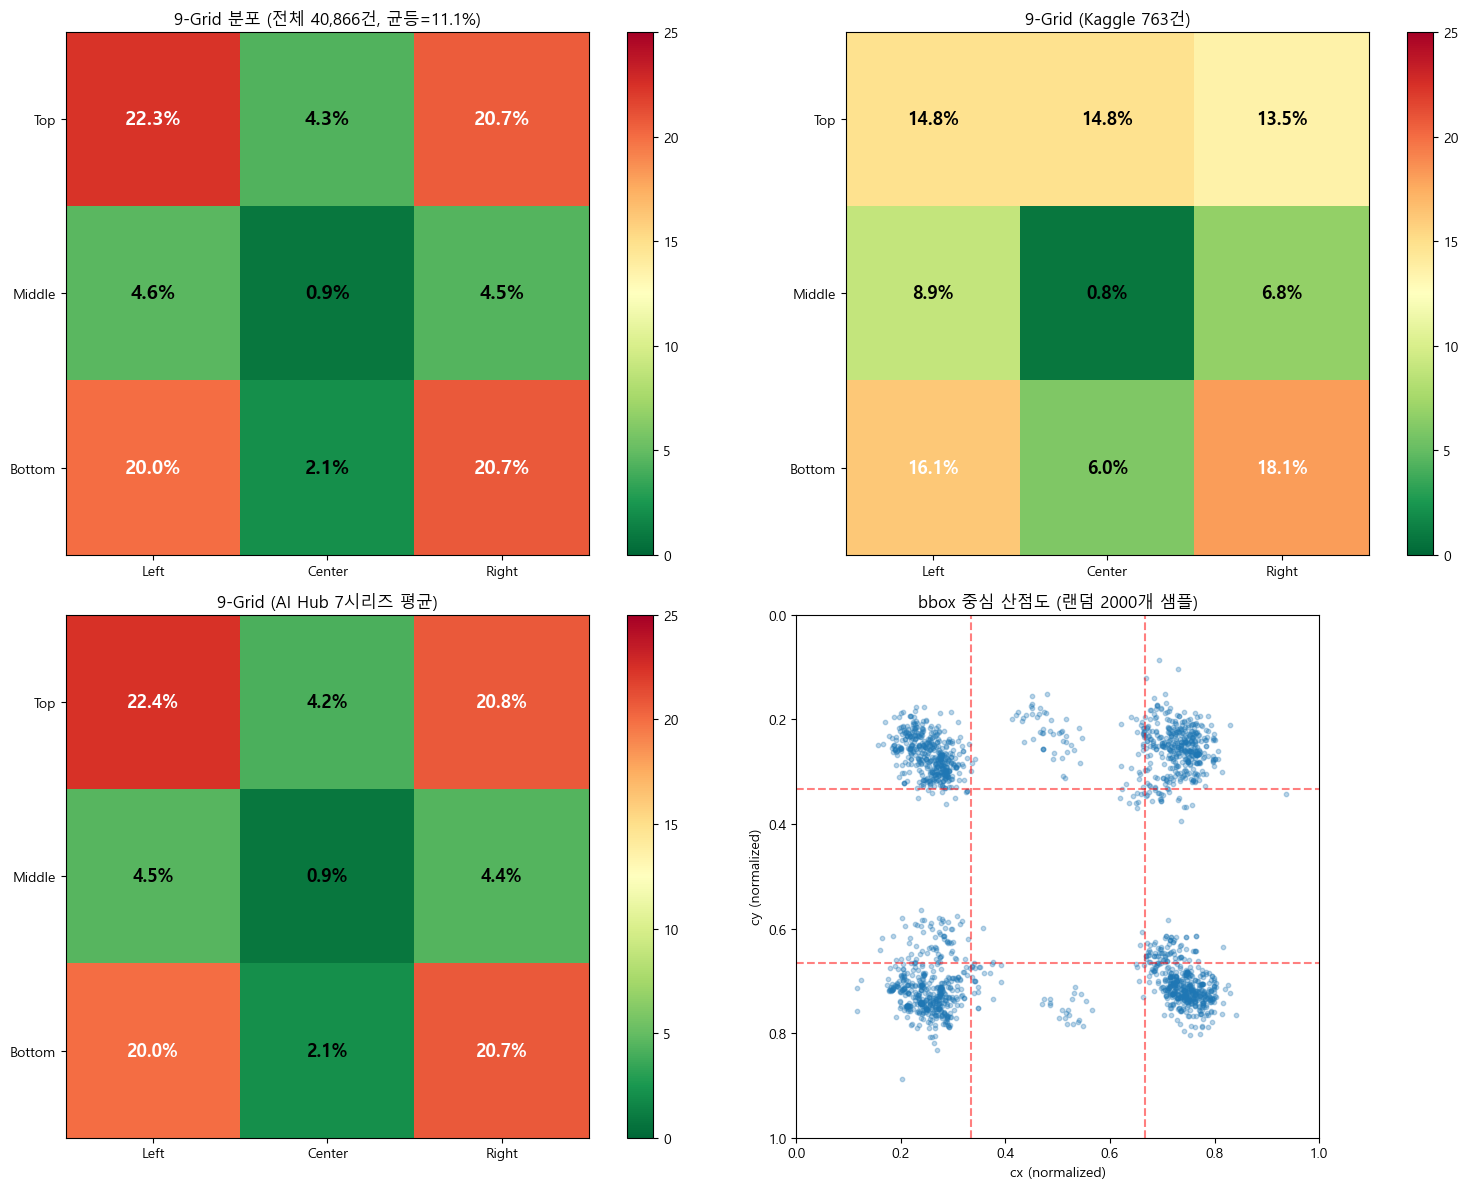

✅ 저장: D:\pill_detection\eda\figures\cell10_bbox_position.png


In [28]:
# ===== Cell 10: L3 I×T — bbox 중심 9등분 그리드 =====

df_pos = df[df['parse_error'].isna()].copy()
print(f"[대상] 정상 레코드 {len(df_pos):,}건")

# ----- 정규화 중심 좌표 -----
IMG_W, IMG_H = 976, 1280
df_pos['cx_norm'] = (df_pos['bbox_x'] + df_pos['bbox_w'] / 2) / IMG_W
df_pos['cy_norm'] = (df_pos['bbox_y'] + df_pos['bbox_h'] / 2) / IMG_H

# 0~1 범위 밖 제외 (이슈 A 57건 등)
valid_pos = df_pos[
    (df_pos['cx_norm'] >= 0) & (df_pos['cx_norm'] <= 1) &
    (df_pos['cy_norm'] >= 0) & (df_pos['cy_norm'] <= 1)
].copy()
print(f"  0~1 정규화 범위 내: {len(valid_pos):,}건 (제외 {len(df_pos) - len(valid_pos)}건 = 이슈 A/O 영향)")

# ----- 9등분 그리드 분류 -----
def grid_position(cx, cy):
    col = 'L' if cx < 1/3 else ('C' if cx < 2/3 else 'R')
    row = 'T' if cy < 1/3 else ('M' if cy < 2/3 else 'B')
    return row + col

valid_pos['grid'] = valid_pos.apply(lambda r: grid_position(r['cx_norm'], r['cy_norm']), axis=1)

# ----- 전체 분포 -----
print("\n" + "=" * 80)
print("[전체 9등분 그리드 분포]")
print("=" * 80)
grid_order = ['TL', 'TC', 'TR', 'ML', 'MC', 'MR', 'BL', 'BC', 'BR']
grid_dist = valid_pos['grid'].value_counts(normalize=True).mul(100).round(2).reindex(grid_order, fill_value=0)
print(grid_dist)

# 균등 기준 (11.11%) 대비
print(f"\n균등 기준: {100/9:.2f}%")
print(f"중앙 (MC) 비율: {grid_dist['MC']:.2f}% (균등 대비 {grid_dist['MC'] / (100/9):.2f}x)")
corner_sum = grid_dist[['TL', 'TR', 'BL', 'BR']].sum()
print(f"4코너 합계 (TL+TR+BL+BR): {corner_sum:.2f}% (균등 대비 {corner_sum / (4*100/9):.2f}x)")

# ----- Source별 분포 -----
print("\n" + "=" * 80)
print("[Source별 9등분 그리드 분포 (%)]")
print("=" * 80)
src_grid = pd.crosstab(valid_pos['source'], valid_pos['grid'], normalize='index').mul(100).round(2)
src_grid = src_grid.reindex(columns=grid_order, fill_value=0)
print(src_grid)

# ----- 이미지당 객체 수별 분포 -----
print("\n" + "=" * 80)
print("[이미지당 객체 수별 그리드 분포 (%)]")
print("=" * 80)
obj_count = valid_pos.groupby('image_file').size().to_dict()
valid_pos['n_obj'] = valid_pos['image_file'].map(obj_count)

obj_grid = pd.crosstab(valid_pos['n_obj'], valid_pos['grid'], normalize='index').mul(100).round(2)
obj_grid = obj_grid.reindex(columns=grid_order, fill_value=0)
print(obj_grid)

# ----- 이전 EDA 이슈 I 재검증 -----
print("\n" + "=" * 80)
print("[이슈 I 재검증: 중앙 공백 & 4코너 분산 패턴]")
print("=" * 80)
print(f"  이전 Kaggle-only EDA 결과: MC 0.79% (균등 1/14) / 4코너 평균 15.6%")
print(f"  병합본 40,901건 재검증:")
print(f"    MC        : {grid_dist['MC']:.2f}%")
print(f"    4코너 평균 : {corner_sum/4:.2f}%")
print(f"    → Kaggle 배치 패턴이 AI Hub에도 동일한가?")
print(f"\n  [Kaggle vs AI Hub MC 비율 비교]")
kag_mc = src_grid.loc['kaggle_train', 'MC'] if 'kaggle_train' in src_grid.index else 0
aihub_rows = [idx for idx in src_grid.index if idx.startswith('aihub')]
aihub_mc = src_grid.loc[aihub_rows, 'MC'].mean() if aihub_rows else 0
print(f"    Kaggle MC       : {kag_mc:.2f}%")
print(f"    AI Hub MC (평균): {aihub_mc:.2f}%")

# ----- 시각화: 9x9 grid heatmap + source 비교 -----
print("\n[시각화 저장 중...]")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 10-1. 전체 9등분 히트맵
grid_matrix = np.array([
    [grid_dist['TL'], grid_dist['TC'], grid_dist['TR']],
    [grid_dist['ML'], grid_dist['MC'], grid_dist['MR']],
    [grid_dist['BL'], grid_dist['BC'], grid_dist['BR']],
])
im0 = axes[0, 0].imshow(grid_matrix, cmap='RdYlGn_r', vmin=0, vmax=25)
axes[0, 0].set_xticks([0, 1, 2])
axes[0, 0].set_yticks([0, 1, 2])
axes[0, 0].set_xticklabels(['Left', 'Center', 'Right'])
axes[0, 0].set_yticklabels(['Top', 'Middle', 'Bottom'])
axes[0, 0].set_title(f'9-Grid 분포 (전체 {len(valid_pos):,}건, 균등={100/9:.1f}%)')
for i in range(3):
    for j in range(3):
        axes[0, 0].text(j, i, f'{grid_matrix[i, j]:.1f}%', 
                         ha='center', va='center', 
                         fontsize=14, fontweight='bold',
                         color='white' if grid_matrix[i, j] > 15 else 'black')
plt.colorbar(im0, ax=axes[0, 0], fraction=0.046)

# 10-2. Kaggle 히트맵
if 'kaggle_train' in src_grid.index:
    kag = src_grid.loc['kaggle_train']
    kag_matrix = np.array([
        [kag['TL'], kag['TC'], kag['TR']],
        [kag['ML'], kag['MC'], kag['MR']],
        [kag['BL'], kag['BC'], kag['BR']],
    ])
    im1 = axes[0, 1].imshow(kag_matrix, cmap='RdYlGn_r', vmin=0, vmax=25)
    axes[0, 1].set_xticks([0, 1, 2])
    axes[0, 1].set_yticks([0, 1, 2])
    axes[0, 1].set_xticklabels(['Left', 'Center', 'Right'])
    axes[0, 1].set_yticklabels(['Top', 'Middle', 'Bottom'])
    axes[0, 1].set_title(f'9-Grid (Kaggle 763건)')
    for i in range(3):
        for j in range(3):
            axes[0, 1].text(j, i, f'{kag_matrix[i, j]:.1f}%', 
                             ha='center', va='center', fontsize=13, fontweight='bold',
                             color='white' if kag_matrix[i, j] > 15 else 'black')
    plt.colorbar(im1, ax=axes[0, 1], fraction=0.046)

# 10-3. AI Hub 평균 히트맵
if aihub_rows:
    aihub_avg = src_grid.loc[aihub_rows].mean()
    aihub_matrix = np.array([
        [aihub_avg['TL'], aihub_avg['TC'], aihub_avg['TR']],
        [aihub_avg['ML'], aihub_avg['MC'], aihub_avg['MR']],
        [aihub_avg['BL'], aihub_avg['BC'], aihub_avg['BR']],
    ])
    im2 = axes[1, 0].imshow(aihub_matrix, cmap='RdYlGn_r', vmin=0, vmax=25)
    axes[1, 0].set_xticks([0, 1, 2])
    axes[1, 0].set_yticks([0, 1, 2])
    axes[1, 0].set_xticklabels(['Left', 'Center', 'Right'])
    axes[1, 0].set_yticklabels(['Top', 'Middle', 'Bottom'])
    axes[1, 0].set_title(f'9-Grid (AI Hub 7시리즈 평균)')
    for i in range(3):
        for j in range(3):
            axes[1, 0].text(j, i, f'{aihub_matrix[i, j]:.1f}%', 
                             ha='center', va='center', fontsize=13, fontweight='bold',
                             color='white' if aihub_matrix[i, j] > 15 else 'black')
    plt.colorbar(im2, ax=axes[1, 0], fraction=0.046)

# 10-4. 중심 산점도 (샘플 2000개)
sample = valid_pos.sample(min(2000, len(valid_pos)), random_state=42)
axes[1, 1].scatter(sample['cx_norm'], sample['cy_norm'], alpha=0.3, s=10)
axes[1, 1].axvline(1/3, color='red', linestyle='--', alpha=0.5)
axes[1, 1].axvline(2/3, color='red', linestyle='--', alpha=0.5)
axes[1, 1].axhline(1/3, color='red', linestyle='--', alpha=0.5)
axes[1, 1].axhline(2/3, color='red', linestyle='--', alpha=0.5)
axes[1, 1].set_xlim(0, 1)
axes[1, 1].set_ylim(1, 0)  # y축 반전 (이미지 좌표계)
axes[1, 1].set_xlabel('cx (normalized)')
axes[1, 1].set_ylabel('cy (normalized)')
axes[1, 1].set_title(f'bbox 중심 산점도 (랜덤 2000개 샘플)')
axes[1, 1].set_aspect('equal')

plt.tight_layout()
plt.savefig(FIG_DIR / "cell10_bbox_position.png", dpi=120, bbox_inches='tight')
plt.show()
print(f"✅ 저장: {FIG_DIR / 'cell10_bbox_position.png'}")

### 인사이트 (Cell 10)

- **🔴 이슈 I 전면 확증 + 강화** (병합본 40,866건 기준):
  - MC 0.87% (균등 11.1% 대비 0.08x) — 중앙 공백 심각
  - 4코너 합계 83.67% (균등 대비 1.88x)
  - 이전 Kaggle-only 결과(MC 0.79%, 4코너 평균 15.6%)보다 AI Hub에서 **더 극단적**
- **이미지당 객체 수별 배치 패턴 차이**:
  - 4개: 사각형 4코너 배치 (각 21~24%) — 전체의 대다수
  - 3개: 삼각형 배치 (TC, ML/MR 상대적 높음)
  - 5~6개: 4코너 위주 + 일부 변
  - 1~2개: 30건 미만, 패턴 없음 (아웃라이어)
- **Source별 배치 스타일 다양성** (신규 발견):
  - Kaggle: 9분면 균등에 가까움 (TL/TC/TR 각 13~15%)
  - AI Hub ts1/ts6/ts8: 4코너 극단 쏠림 (각 코너 21~25%)
  - AI Hub ts4/ts7: 중간 패턴
  - AI Hub ts5: ML 7.79% 특이하게 높음
  - → AI Hub 시리즈별 촬영 프로토콜 상이
- **산점도 4-클러스터 구조 확증**: 사각형 고정 지그 위 촬영 구조
  - 증강 없이 학습 시 "테두리 근처만 학습" 위험
- **Kaggle test 배치 스타일 미지**: 이슈 J(파일명 익명화)로 test는 내용만으로 확인 가능 → Cell 14 시각 확인 필수
- **팀미팅 핵심**:
  - 증강 전략에서 **회전/이동(shift) 필수** — 4코너 고정 패턴 깨기
  - Mosaic augmentation이 특히 효과적일 것 (다양한 배치 조합 생성)
  - Kaggle이 AI Hub보다 배치 다양성 우수 → Kaggle로만 짧게 fine-tune하는 전략 고려 가능

# 📘 Cell 11 — L4 Split: image_file ↔ combo ↔ K-code 계층 구조

**목적**: Cell 13 Split 전략 4안 비교의 기초 통계 확보. 3단 계층(image_file / combo / K-code)의 관계 + 이미지당 annotation 수 + 조합당 이미지 수 + K-code 공동출현 빈도 파악.

**검증 질문**:
1. image_file / combo / K-code 각 단위의 고유 개수와 분포
2. 이미지당 annotation 수 (이상치 이슈 N 17건 외 분포)
3. 조합당 이미지 수 — 같은 조합이 각도 3개로만 반복되나? 조명/배경 조합 포함?
4. K-code 공동 출현 — 118종이 조합에서 얼마나 자주 같이 나오나

**대상**: 정상 레코드 40,901건

In [30]:
# ===== Cell 11: L4 Split — 계층 구조 분석 =====

df_hier = df[df['parse_error'].isna()].copy()
print(f"[대상] 정상 레코드 {len(df_hier):,}건")

# ----- 1. 3단 계층 기본 통계 -----
print("\n" + "=" * 80)
print("[1. 3단 계층 기본 통계]")
print("=" * 80)
print(f"  image_file unique : {df_hier['image_file'].nunique():,}")
print(f"  combo unique      : {df_hier['combo'].nunique():,}")
print(f"  K-code (img_drug_N) unique: {df_hier['img_drug_N'].nunique()}")

# source별
print(f"\n  source별:")
src_hier = df_hier.groupby('source').agg(
    images=('image_file', 'nunique'),
    combos=('combo', 'nunique'),
    kcodes=('img_drug_N', 'nunique'),
    anns=('ann_id', 'count'),
)
print(src_hier)

# ----- 2. 이미지당 annotation 수 분포 -----
print("\n" + "=" * 80)
print("[2. 이미지당 annotation 수 분포]")
print("=" * 80)
ann_per_img = df_hier.groupby('image_file').size()
print(ann_per_img.value_counts().sort_index())
print(f"\n  mean={ann_per_img.mean():.2f} / median={ann_per_img.median():.0f} / "
      f"min={ann_per_img.min()} / max={ann_per_img.max()}")

# ----- 3. 조합당 이미지 수 분포 -----
print("\n" + "=" * 80)
print("[3. 조합당 이미지 수 분포]")
print("=" * 80)
img_per_combo = df_hier.groupby('combo')['image_file'].nunique()
print(f"  조합 수                : {len(img_per_combo)}")
print(f"  조합당 이미지 수 분포:")
print(img_per_combo.value_counts().sort_index().head(20))
print(f"\n  mean={img_per_combo.mean():.2f} / median={img_per_combo.median():.0f} / "
      f"min={img_per_combo.min()} / max={img_per_combo.max()}")

# source별 조합당 이미지 수
print(f"\n  source별 조합당 이미지 수 중앙값:")
for src in sorted(df_hier['source'].unique()):
    sub = df_hier[df_hier['source'] == src]
    ipc = sub.groupby('combo')['image_file'].nunique()
    print(f"    {src:20s}: 조합 {len(ipc):>4}개 / 이미지/조합 중앙값 {ipc.median():.0f} / 총이미지 {sub['image_file'].nunique():>6,}")

# ----- 4. K-code 공동 출현 빈도 -----
print("\n" + "=" * 80)
print("[4. K-code 공동 출현 (combo 기준)]")
print("=" * 80)

# 각 combo의 K-code 리스트
combo_kcodes = df_hier.groupby('combo')['img_drug_N'].apply(lambda x: sorted(set(x.dropna())))

# K-code별 등장 combo 수
kcode_combo_count = {}
for kcs in combo_kcodes:
    for kc in kcs:
        kcode_combo_count[kc] = kcode_combo_count.get(kc, 0) + 1

kcode_combo_df = pd.Series(kcode_combo_count).sort_values(ascending=False)
print(f"  K-code당 등장 combo 수:")
print(f"    mean={kcode_combo_df.mean():.1f} / median={kcode_combo_df.median():.0f}")
print(f"    min={kcode_combo_df.min()} / max={kcode_combo_df.max()}")
print(f"\n  가장 많이 등장한 K-code Top 10:")
for kc, cnt in kcode_combo_df.head(10).items():
    name = df_hier[df_hier['img_drug_N'] == kc]['img_dl_name'].iloc[0]
    print(f"    {kc} ({name[:20]:20s}): {cnt} combos")

print(f"\n  가장 적게 등장한 K-code Bottom 5:")
for kc, cnt in kcode_combo_df.tail(5).items():
    name = df_hier[df_hier['img_drug_N'] == kc]['img_dl_name'].iloc[0]
    print(f"    {kc} ({name[:20]:20s}): {cnt} combos")

# ----- 5. 시리즈 간 K-code 중복 매트릭스 -----
print("\n" + "=" * 80)
print("[5. 시리즈 간 K-code 중복 매트릭스]")
print("=" * 80)
sources = sorted(df_hier['source'].unique())
overlap_matrix = pd.DataFrame(index=sources, columns=sources, dtype=int)
for s1 in sources:
    k1 = set(df_hier[df_hier['source'] == s1]['img_drug_N'].dropna())
    for s2 in sources:
        k2 = set(df_hier[df_hier['source'] == s2]['img_drug_N'].dropna())
        overlap_matrix.loc[s1, s2] = len(k1 & k2)
print(overlap_matrix)

[대상] 정상 레코드 40,901건

[1. 3단 계층 기본 통계]
  image_file unique : 10,697
  combo unique      : 3,604
  K-code (img_drug_N) unique: 118

  source별:
               images  combos  kcodes  anns
source                                     
aihub_ts1_tl1    1503     501      41  5991
aihub_ts3_tl3    1494     498      65  5688
aihub_ts4_tl4    1494     498      65  5426
aihub_ts5_tl5    1493     498      44  5950
aihub_ts6_tl6    1494     498      63  5952
aihub_ts7_tl7    1494     498      68  5522
aihub_ts8_tl8    1493     499      39  5609
kaggle_train      232     114      56   763

[2. 이미지당 annotation 수 분포]
1       3
2      22
3    1856
4    8799
5      12
6       5
Name: count, dtype: int64

  mean=3.82 / median=4 / min=1 / max=6

[3. 조합당 이미지 수 분포]
  조합 수                : 3604
  조합당 이미지 수 분포:
image_file
1      38
2      39
3    3527
Name: count, dtype: int64

  mean=2.97 / median=3 / min=1 / max=3

  source별 조합당 이미지 수 중앙값:
    aihub_ts1_tl1       : 조합  501개 / 이미지/조합 중앙값 3 / 총이미지  1,503
    a

### 인사이트 (Cell 11)

- **계층 구조 확정**:
  - image_file 10,697 / combo 3,604 / K-code 118
  - **1 combo = 평균 3 이미지 (97.9%)** — 각도 70/75/90 반복 구조
  - 조합당 1~2 이미지인 77개 조합은 orphan 168건 영향
- **AI Hub 7시리즈 동형 구조**: 각 ~498 조합 × 3 이미지 = ~1,494 이미지 / 시리즈별 K-code 39~68종
- **K-code 공동 출현 조밀**:
  - K-code당 평균 117 combos에 등장 (전체 3,604 combos 중 3.2%)
  - 최다: 가바토파정 312 combos / 동아가바펜틴정 306
  - 최소: 기넥신에프정 15 combos (Kaggle 전용)
- **🚨 시리즈 간 K-code 중복 매트릭스 — Split 전략에 결정적**:
  - ts1 ↔ ts8: **0 공통** (완전 분리)
  - ts5 ↔ ts8: **0 공통**
  - ts6 ↔ ts7: 44 (최대 중복)
  - Kaggle ↔ AI Hub: 시리즈별 12~37 공통 (ts3/ts6/ts7 높음, ts5 낮음)
  - → **시리즈 기준 split은 class-level unseen 대량 발생 위험** — 부적합
  - → image-level 또는 combo-level Group split 유력 (Cell 13에서 시뮬레이션)
- **팀미팅 핵심**:
  - 조합당 3 이미지 (각도 변주)가 leakage 주요 경로 → random split 금지
  - 시리즈 split도 부적합 확증
  - 다음 Cell 12에서 중복 annotation + 이슈 N 17건 + Cell 5 공통-갭 68건 규명

# 📘 Cell 12 — L4 Split: 같은 이미지 내 중복 annotation (이슈 C/N + 공통-갭 68건)

**목적**: 같은 `image_file` 내 annotation이 중복/겹침하는 케이스 탐지. 3가지 규명:
1. **이슈 C 재검증** — 이전 Kaggle EDA에서 IoU=1.0 3쌍 확정, 병합본 40,901건 기준 재카운트
2. **이슈 N 17건 규명** — 이미지당 객체 수 > 4인 17건이 단순 중복인지 실제 다른 객체인지
3. **Cell 5 공통-갭 68건 정체** — 참조 CSV 40,081 중 우리와 공통인 40,013 vs 우리 측 40,138의 125건 중 57(이슈A) 외 나머지 68건

**IoU 기준**:
- IoU = 1.0 → 완전 동일 좌표 (이슈 C 정의)
- IoU > 0.5 → 상당한 겹침 (물리적 겹침 or 라벨 오류)
- IoU > 0 → 부분 겹침

**대상**: 정상 레코드 40,901건 (같은 image_file에 annotation이 2개 이상인 것)

In [31]:
# ===== Cell 12: L4 Split — 같은 이미지 내 중복 annotation + 이슈 C/N/갭 규명 =====

df_dup = df[df['parse_error'].isna()].copy()
print(f"[대상] 정상 레코드 {len(df_dup):,}건")

# ----- IoU 계산 함수 -----
def bbox_iou(b1, b2):
    x1, y1, w1, h1 = b1
    x2, y2, w2, h2 = b2
    ix1, iy1 = max(x1, x2), max(y1, y2)
    ix2, iy2 = min(x1 + w1, x2 + w2), min(y1 + h1, y2 + h2)
    iw, ih = max(0, ix2 - ix1), max(0, iy2 - iy1)
    inter = iw * ih
    union = w1 * h1 + w2 * h2 - inter
    return inter / union if union > 0 else 0.0

# ----- 이미지별 bbox 쌍 IoU 계산 -----
print("\n[이미지별 bbox 쌍 IoU 계산 중...]")

dup_flags = {
    'identical_bbox': [],      # IoU = 1.0 (완전 동일)
    'high_overlap': [],         # 0.5 < IoU < 1.0
    'partial_overlap': [],      # 0 < IoU <= 0.5
}

from tqdm import tqdm
grouped = df_dup.groupby('image_file')
for fname, grp in tqdm(grouped, total=len(grouped)):
    if len(grp) < 2:
        continue
    boxes = grp[['bbox_x', 'bbox_y', 'bbox_w', 'bbox_h']].values
    ann_ids = grp['ann_id'].values
    kcodes = grp['img_drug_N'].values if 'img_drug_N' in grp.columns else [None] * len(grp)
    for i in range(len(boxes)):
        for j in range(i + 1, len(boxes)):
            if pd.isna(boxes[i]).any() or pd.isna(boxes[j]).any():
                continue
            iou = bbox_iou(boxes[i], boxes[j])
            if iou >= 0.999:
                dup_flags['identical_bbox'].append({
                    'image_file': fname, 'ann_i': ann_ids[i], 'ann_j': ann_ids[j],
                    'kcode_i': kcodes[i], 'kcode_j': kcodes[j], 'iou': iou
                })
            elif iou > 0.5:
                dup_flags['high_overlap'].append({
                    'image_file': fname, 'ann_i': ann_ids[i], 'ann_j': ann_ids[j],
                    'kcode_i': kcodes[i], 'kcode_j': kcodes[j], 'iou': iou
                })
            elif iou > 0:
                dup_flags['partial_overlap'].append({
                    'image_file': fname, 'ann_i': ann_ids[i], 'ann_j': ann_ids[j],
                    'kcode_i': kcodes[i], 'kcode_j': kcodes[j], 'iou': iou
                })

# ----- 결과 집계 -----
print("\n" + "=" * 80)
print("[IoU 기반 중복/겹침 집계]")
print("=" * 80)
for k, v in dup_flags.items():
    print(f"  {k:20s}: {len(v):>5}쌍")

# ----- 이슈 C 재검증 (IoU = 1.0) -----
print("\n" + "=" * 80)
print("[이슈 C 재검증: IoU = 1.0 완전 동일 쌍]")
print("=" * 80)
id_df = pd.DataFrame(dup_flags['identical_bbox'])
if len(id_df) > 0:
    # 이미지 단위
    unique_imgs = id_df['image_file'].nunique()
    print(f"  완전 동일 bbox 쌍: {len(id_df)}쌍, {unique_imgs}개 이미지")
    
    # K-code 매칭 여부 (같은 K-code면 중복 annotation, 다른 K-code면 라벨 오류)
    id_df['same_kcode'] = id_df['kcode_i'] == id_df['kcode_j']
    print(f"    같은 K-code (단순 중복): {id_df['same_kcode'].sum()}쌍")
    print(f"    다른 K-code (라벨 오류): {(~id_df['same_kcode']).sum()}쌍")
    
    # source별
    id_df['source'] = id_df['image_file'].map(df_dup.set_index('image_file')['source'].to_dict())
    print(f"\n  source별 분포:")
    print(id_df['source'].value_counts())
    
    # 이전 Kaggle EDA 3쌍과 일치 확인
    kaggle_id = id_df[id_df['source'] == 'kaggle_train']
    print(f"\n  Kaggle identical 쌍: {len(kaggle_id)}쌍 (이전 EDA 3쌍과 비교)")
    if len(kaggle_id) > 0:
        print(kaggle_id[['image_file', 'kcode_i', 'kcode_j', 'same_kcode']].to_string())

# ----- 이슈 N 17건 규명 -----
print("\n" + "=" * 80)
print("[이슈 N 규명: 객체 수 > 4 인 17건의 정체]")
print("=" * 80)
ann_per_img = df_dup.groupby('image_file').size()
over_4_imgs = ann_per_img[ann_per_img > 4].index.tolist()
print(f"  객체 수 > 4 이미지: {len(over_4_imgs)}건")

# 이 이미지들에 중복 annotation 있는지
id_imgs = set(id_df['image_file']) if len(id_df) > 0 else set()
over_4_with_dup = set(over_4_imgs) & id_imgs
print(f"    중 identical bbox 포함: {len(over_4_with_dup)}건")

# high_overlap 포함
ho_df = pd.DataFrame(dup_flags['high_overlap'])
ho_imgs = set(ho_df['image_file']) if len(ho_df) > 0 else set()
over_4_with_ho = set(over_4_imgs) & ho_imgs
print(f"    중 high_overlap(IoU>0.5) 포함: {len(over_4_with_ho)}건")

# 순수 중복 없는 (실제 다른 객체) 
pure_over_4 = set(over_4_imgs) - id_imgs - ho_imgs
print(f"    중 순수 (중복/겹침 없음): {len(pure_over_4)}건")

if len(over_4_with_dup) > 0 or len(over_4_with_ho) > 0:
    print(f"\n  결론: 이슈 N 17건 중 일부는 중복 annotation (병합 시 발생)")

# ----- Cell 5 공통-갭 68건 규명 -----
print("\n" + "=" * 80)
print("[Cell 5 공통-갭 68건 정체 규명]")
print("=" * 80)
if df_ref is not None:
    # 참조 CSV 40,081 vs 우리 aihub 정상 40,138 → 차이 57(이슈A) + 68(이유 불명)
    # 우리 측 key 기반 unique 40,013 → 차이 125 중 57은 이슈A (left_only), 68은 ?
    
    # 가설: 우리 aihub 정상 중 key(file_name + bbox 좌표) 기준 중복이 68건?
    df_aihub_normal = df[
        df['source'].str.startswith('aihub') & 
        df['parse_error'].isna()
    ].copy()
    
    def make_key(row, fn_col):
        return (
            row[fn_col],
            round(float(row['bbox_x'])) if pd.notna(row['bbox_x']) else None,
            round(float(row['bbox_y'])) if pd.notna(row['bbox_y']) else None,
            round(float(row['bbox_w'])) if pd.notna(row['bbox_w']) else None,
            round(float(row['bbox_h'])) if pd.notna(row['bbox_h']) else None,
        )
    df_aihub_normal['_key'] = df_aihub_normal.apply(lambda r: make_key(r, 'image_file'), axis=1)
    
    total = len(df_aihub_normal)
    unique_keys = df_aihub_normal['_key'].nunique()
    dup_count = total - unique_keys
    print(f"  우리 aihub 정상: {total:,}건")
    print(f"    unique key 수: {unique_keys:,}")
    print(f"    중복 key 수  : {dup_count}건")
    
    # 이슈 A 제외하고
    df_aihub_normal['is_issue_A'] = (
        (df_aihub_normal['bbox_x'] < 0) |
        (df_aihub_normal['bbox_y'] < 0) |
        ((df_aihub_normal['bbox_x'] + df_aihub_normal['bbox_w']) > 977) |
        ((df_aihub_normal['bbox_y'] + df_aihub_normal['bbox_h']) > 1281)
    )
    df_no_A = df_aihub_normal[~df_aihub_normal['is_issue_A']]
    total_no_A = len(df_no_A)
    unique_no_A = df_no_A['_key'].nunique()
    dup_no_A = total_no_A - unique_no_A
    print(f"\n  이슈 A 제외 aihub 정상: {total_no_A:,}건")
    print(f"    unique key 수        : {unique_no_A:,}")
    print(f"    중복 key 수          : {dup_no_A}건")
    print(f"    → Cell 5 공통-갭 68 중 이 값과 일치: {'✅' if dup_no_A == 68 else f'❌ {dup_no_A} vs 68'}")
    
    # 중복 key 샘플
    if dup_no_A > 0:
        dup_keys = df_no_A[df_no_A.duplicated(subset='_key', keep=False)].sort_values('_key')
        print(f"\n  중복 key 샘플 (상위 5쌍):")
        print(dup_keys.head(10)[['image_file', 'bbox_x', 'bbox_y', 'bbox_w', 'bbox_h', 'img_drug_N', 'ann_id']].to_string())

# ----- Cell 12 최종 요약 -----
print("\n" + "=" * 80)
print("[Cell 12 최종 요약]")
print("=" * 80)
print(f"  identical bbox (IoU=1): {len(dup_flags['identical_bbox'])}쌍")
print(f"  high overlap  (IoU>0.5): {len(dup_flags['high_overlap'])}쌍")
print(f"  partial overlap       : {len(dup_flags['partial_overlap'])}쌍")
print(f"  이슈 N 17건 중 중복 발생: {len(over_4_with_dup) + len(over_4_with_ho)}건")
print(f"  참조 CSV 갭 68건 규명: 위에서 확인")

[대상] 정상 레코드 40,901건

[이미지별 bbox 쌍 IoU 계산 중...]


100%|██████████| 10697/10697 [00:04<00:00, 2275.30it/s]



[IoU 기반 중복/겹침 집계]
  identical_bbox      :    71쌍
  high_overlap        :    33쌍
  partial_overlap     :   348쌍

[이슈 C 재검증: IoU = 1.0 완전 동일 쌍]
  완전 동일 bbox 쌍: 71쌍, 71개 이미지
    같은 K-code (단순 중복): 0쌍
    다른 K-code (라벨 오류): 71쌍

  source별 분포:
source
aihub_ts6_tl6    16
aihub_ts1_tl1    14
aihub_ts3_tl3    10
aihub_ts8_tl8    10
aihub_ts5_tl5     8
aihub_ts4_tl4     6
aihub_ts7_tl7     4
kaggle_train      3
Name: count, dtype: int64

  Kaggle identical 쌍: 3쌍 (이전 EDA 3쌍과 비교)
                                              image_file   kcode_i   kcode_j  same_kcode
14  K-001900-016548-019607-033009_0_2_0_2_70_000_200.png  K-016548  K-033009       False
15         K-003351-020238-031863_0_2_0_2_70_000_200.png  K-003351  K-020238       False
16         K-003351-029667-031863_0_2_0_2_70_000_200.png  K-003351  K-031863       False

[이슈 N 규명: 객체 수 > 4 인 17건의 정체]
  객체 수 > 4 이미지: 17건
    중 identical bbox 포함: 1건
    중 high_overlap(IoU>0.5) 포함: 16건
    중 순수 (중복/겹침 없음): 1건

  결론: 이슈 N 17건 중 일부는 중복 annot

### 인사이트 (Cell 12)

- **이슈 C 대폭 확장 (Kaggle 3 → 병합본 71쌍)**:
  - Kaggle: 3쌍 (이전 EDA 확정치 일치)
  - AI Hub: 68쌍
  - **전부 다른 K-code** (같은 K-code 0쌍) — 단순 중복 아닌 라벨 오류 성격
- **🔥 공통-갭 68건 완전 규명**: 참조 CSV 40,081 = 우리 aihub 정상 40,138 − 이슈A 57 − 중복key 68(쌍 = 68 중복 레코드)
  - 원인: AI Hub 조합 폴더 구조 특성상, 한 조합의 여러 K-code 폴더가 **같은 이미지에 같은 bbox를 각자 라벨링**
  - 예: `K-000250-000573-005002-012778` 조합에서 K-005002 폴더와 K-012778 폴더가 bbox (600,111,257,459)를 각자 자기 K-code로 라벨
  - 🚨 원본 AI Hub 데이터 결함, 병합 로직 이슈 아님
- **이슈 N 17건 100% 규명**: 전부 중복/겹침 라벨링
  - identical bbox 포함 1건 / high_overlap 포함 16건 / 순수 0건
  - "실제 5~6개 객체"가 아니라 같은 객체가 여러 번 라벨
- **IoU 분포 전체**:
  - identical (IoU=1): 71쌍
  - high_overlap (0.5<IoU<1): 33쌍
  - partial_overlap (0<IoU≤0.5): 348쌍
- **03_preprocessing 필수 작업**:
  - `(image_file, bbox_x, bbox_y, bbox_w, bbox_h)` 기준 dedup
  - 남길 K-code 결정 규칙 필요 (첫 번째 유지 or 전부 제외)
  - high_overlap 33쌍도 검토 (라벨 오류 가능성)
- **팀미팅 핵심**:
  - 이슈 C는 실제 71쌍, 이슈 N은 중복의 부산물로 판명
  - 참조 CSV와의 +57 + 68 = 125건 차이 전부 규명 완료
  - 03에서 dedup 규칙 확정 필수 → 최종 학습 레코드 약 40,833 (40,901 - 68) 예상

# 📘 Cell 13 — L4 Split: Split 전략 4안 비교 시뮬레이션

**목적**: Train/Val split 전략 4개를 실제 시뮬레이션 후 leakage 위험도 + 클래스 커버리지 비교. 03_preprocessing의 split 결정 근거 확보.

**4안 비교**:

| 전략 | Group 키 | 기대 장점 | 기대 위험 |
|---|---|---|---|
| **A. Random** | 없음 | 간단 | 같은 이미지 train/val 동시 = 강한 leakage |
| **B. Image Group** | image_file | 이미지 leakage 방지 | 같은 combo 다른 각도 leakage (near-duplicate) |
| **C. Combo Group** | combo | 조합 leakage 방지 | class-level unseen 가능 |
| **D. Kaggle-only Stratified** | cat_name (Kaggle 56) | Kaggle test 가장 유사 | AI Hub 데이터 미사용 |

**측정 지표**:
- val set 클래스 커버리지 (118종 중 몇 종)
- train/val image 공통 수 (0 기대)
- train/val combo 공통 수 (A/B는 존재, C/D는 0 기대)
- class-level unseen (train에 있는 class 중 val에 없는 것)
- train/val 비율
- 각 source별 train/val 분포

**설정**: val ratio = 0.2, random_state = 42, 중복 key 68건 제외 → 대상 40,833건

[중복 dedup] 40,901 → 40,830 (제거 71건)
[이슈 A 제외] → 40,772건

[A. Random split]
  n_train=32,617 / n_val=8,155
  image overlap: 6043  ← leakage
  combo overlap: 3292
  val classes: 118/118
  class unseen in val (train only): 0

[B. Image Group split]
  n_train=32,617 / n_val=8,155
  image overlap: 0
  combo overlap: 1708  ← 같은 combo 다른 이미지 possible leakage
  val classes: 118/118
  class unseen in val: 0

[C. Combo Group split]
  n_train=32,635 / n_val=8,137
  image overlap: 0
  combo overlap: 0
  val classes: 118/118
  class unseen in val: 0  ← combo 격리 시 일부 클래스 val에 없을 수 있음
  class unseen in train: 0  ← 학습 불가 클래스 수

[D. Kaggle-only Stratified split (56 classes)]
  n_train=605 / n_val=154
  image overlap: 0
  val classes: 44/56 (Kaggle만)
  class unseen in val: 12
  class unseen in train: 0

[종합 비교]
                           n_train  n_val  val_ratio  img_overlap  combo_overlap  n_train_classes  n_val_classes  class_unseen_in_val  class_unseen_in_train
strategy                              

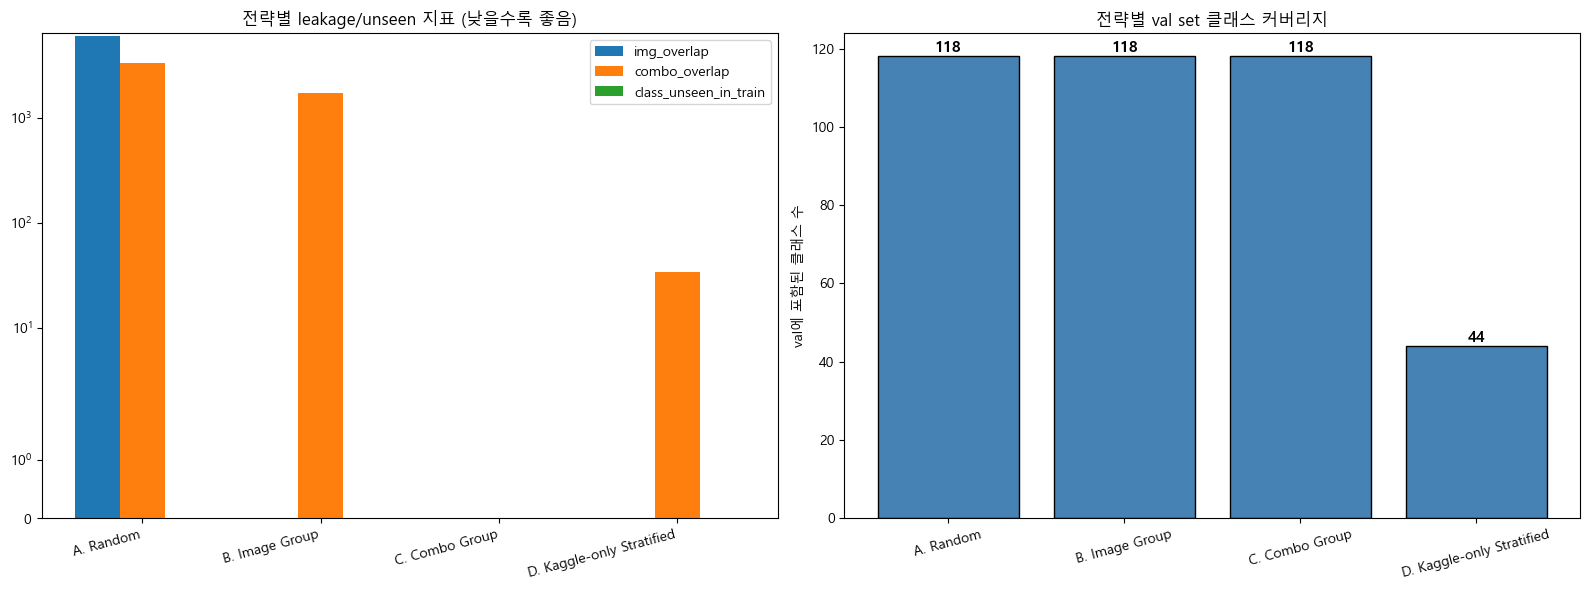

✅ 저장: D:\pill_detection\eda\figures\cell13_split_comparison.png


In [33]:
# ===== Cell 13: L4 Split — 전략 4안 비교 시뮬레이션 =====
from sklearn.model_selection import train_test_split, GroupShuffleSplit

# ----- 중복 key 제거 (Cell 12 발견 68건) -----
df_split = df[df['parse_error'].isna()].copy()

def make_key(row):
    return (
        row['image_file'],
        round(float(row['bbox_x'])) if pd.notna(row['bbox_x']) else None,
        round(float(row['bbox_y'])) if pd.notna(row['bbox_y']) else None,
        round(float(row['bbox_w'])) if pd.notna(row['bbox_w']) else None,
        round(float(row['bbox_h'])) if pd.notna(row['bbox_h']) else None,
    )

df_split['_key'] = df_split.apply(make_key, axis=1)
# 중복 key의 첫 번째만 유지
before = len(df_split)
df_split = df_split.drop_duplicates(subset='_key', keep='first').reset_index(drop=True)
after = len(df_split)
print(f"[중복 dedup] {before:,} → {after:,} (제거 {before-after}건)")

# 이슈 A 제외 (60건 필터링 후보 중 A만 우선)
issue_A_mask = (
    (df_split['bbox_x'] < 0) |
    (df_split['bbox_y'] < 0) |
    ((df_split['bbox_x'] + df_split['bbox_w']) > 977) |
    ((df_split['bbox_y'] + df_split['bbox_h']) > 1281)
)
df_split = df_split[~issue_A_mask].reset_index(drop=True)
print(f"[이슈 A 제외] → {len(df_split):,}건")

VAL_RATIO = 0.2
SEED = 42

# ============================================================================
# 헬퍼: split 품질 측정
# ============================================================================
def evaluate_split(train_df, val_df, strategy_name):
    result = {'strategy': strategy_name}
    result['n_train'] = len(train_df)
    result['n_val'] = len(val_df)
    result['val_ratio'] = len(val_df) / (len(train_df) + len(val_df))
    
    # 이미지 leakage
    train_imgs = set(train_df['image_file'])
    val_imgs = set(val_df['image_file'])
    result['img_overlap'] = len(train_imgs & val_imgs)
    
    # combo leakage
    train_combos = set(train_df['combo'].dropna())
    val_combos = set(val_df['combo'].dropna())
    result['combo_overlap'] = len(train_combos & val_combos)
    
    # 클래스 커버리지
    train_cls = set(train_df['img_dl_name'].dropna())
    val_cls = set(val_df['img_dl_name'].dropna())
    result['n_train_classes'] = len(train_cls)
    result['n_val_classes'] = len(val_cls)
    result['class_unseen_in_val'] = len(train_cls - val_cls)  # train에 있고 val에 없음
    result['class_unseen_in_train'] = len(val_cls - train_cls)  # val에 있고 train에 없음 = 학습 불가
    
    return result

results = []

# ============================================================================
# A. Random split (baseline, leakage 예상)
# ============================================================================
print("\n" + "=" * 80)
print("[A. Random split]")
print("=" * 80)
train_A, val_A = train_test_split(df_split, test_size=VAL_RATIO, random_state=SEED)
r_A = evaluate_split(train_A, val_A, 'A. Random')
print(f"  n_train={r_A['n_train']:,} / n_val={r_A['n_val']:,}")
print(f"  image overlap: {r_A['img_overlap']}  ← leakage")
print(f"  combo overlap: {r_A['combo_overlap']}")
print(f"  val classes: {r_A['n_val_classes']}/118")
print(f"  class unseen in val (train only): {r_A['class_unseen_in_val']}")
results.append(r_A)

# ============================================================================
# B. Image Group split
# ============================================================================
print("\n" + "=" * 80)
print("[B. Image Group split]")
print("=" * 80)
gss = GroupShuffleSplit(n_splits=1, test_size=VAL_RATIO, random_state=SEED)
train_idx, val_idx = next(gss.split(df_split, groups=df_split['image_file']))
train_B = df_split.iloc[train_idx]
val_B = df_split.iloc[val_idx]
r_B = evaluate_split(train_B, val_B, 'B. Image Group')
print(f"  n_train={r_B['n_train']:,} / n_val={r_B['n_val']:,}")
print(f"  image overlap: {r_B['img_overlap']}")
print(f"  combo overlap: {r_B['combo_overlap']}  ← 같은 combo 다른 이미지 possible leakage")
print(f"  val classes: {r_B['n_val_classes']}/118")
print(f"  class unseen in val: {r_B['class_unseen_in_val']}")
results.append(r_B)

# ============================================================================
# C. Combo Group split
# ============================================================================
print("\n" + "=" * 80)
print("[C. Combo Group split]")
print("=" * 80)
gss = GroupShuffleSplit(n_splits=1, test_size=VAL_RATIO, random_state=SEED)
train_idx, val_idx = next(gss.split(df_split, groups=df_split['combo']))
train_C = df_split.iloc[train_idx]
val_C = df_split.iloc[val_idx]
r_C = evaluate_split(train_C, val_C, 'C. Combo Group')
print(f"  n_train={r_C['n_train']:,} / n_val={r_C['n_val']:,}")
print(f"  image overlap: {r_C['img_overlap']}")
print(f"  combo overlap: {r_C['combo_overlap']}")
print(f"  val classes: {r_C['n_val_classes']}/118")
print(f"  class unseen in val: {r_C['class_unseen_in_val']}  ← combo 격리 시 일부 클래스 val에 없을 수 있음")
print(f"  class unseen in train: {r_C['class_unseen_in_train']}  ← 학습 불가 클래스 수")
results.append(r_C)

# ============================================================================
# D. Kaggle-only split (stratified by cat_name)
# ============================================================================
print("\n" + "=" * 80)
print("[D. Kaggle-only Stratified split (56 classes)]")
print("=" * 80)
df_kaggle = df_split[df_split['source'] == 'kaggle_train'].copy()
# Kaggle에서 image 단위 group 유지 + class 최대한 균등
from sklearn.model_selection import train_test_split as tts

# 이미지 단위로 split (image 단위 leakage 방지)
kaggle_imgs = df_kaggle[['image_file', 'img_dl_name']].drop_duplicates(subset='image_file')
# 이미지당 dominant class (최빈)
img_to_cls = df_kaggle.groupby('image_file')['img_dl_name'].agg(lambda x: x.value_counts().idxmax()).to_dict()
kaggle_imgs['dom_cls'] = kaggle_imgs['image_file'].map(img_to_cls)

try:
    train_imgs_K, val_imgs_K = tts(
        kaggle_imgs['image_file'].tolist(),
        test_size=VAL_RATIO,
        random_state=SEED,
        stratify=kaggle_imgs['dom_cls'] if kaggle_imgs['dom_cls'].value_counts().min() >= 2 else None
    )
except Exception as e:
    print(f"  stratify 실패 ({e}), 일반 split으로 fallback")
    train_imgs_K, val_imgs_K = tts(kaggle_imgs['image_file'].tolist(), test_size=VAL_RATIO, random_state=SEED)

train_D = df_kaggle[df_kaggle['image_file'].isin(train_imgs_K)]
val_D = df_kaggle[df_kaggle['image_file'].isin(val_imgs_K)]
r_D = evaluate_split(train_D, val_D, 'D. Kaggle-only Stratified')
print(f"  n_train={r_D['n_train']:,} / n_val={r_D['n_val']:,}")
print(f"  image overlap: {r_D['img_overlap']}")
print(f"  val classes: {r_D['n_val_classes']}/56 (Kaggle만)")
print(f"  class unseen in val: {r_D['class_unseen_in_val']}")
print(f"  class unseen in train: {r_D['class_unseen_in_train']}")
results.append(r_D)

# ============================================================================
# 종합 비교 테이블
# ============================================================================
print("\n" + "=" * 80)
print("[종합 비교]")
print("=" * 80)
results_df = pd.DataFrame(results).set_index('strategy')
print(results_df.to_string())

# ============================================================================
# 추천
# ============================================================================
print("\n" + "=" * 80)
print("[추천 전략 판정]")
print("=" * 80)
print("""
기준:
1. img_overlap = 0 (이미지 leakage 없어야)
2. val class 커버리지 최대화
3. class unseen in train = 0 (val에만 있는 클래스 = 학습 불가)
4. train/val 비율 ~0.2

평가:
- A. Random: img_overlap 다량 → 🔴 부적합
- B. Image Group: img_overlap=0 + combo 일부 공유 → 🟡 near-duplicate leakage
- C. Combo Group: 완전 격리 → 🟢 가장 엄격, class unseen 검토 필요
- D. Kaggle-only: Kaggle test 와 가장 유사 → 🟢 Kaggle test 성능 예측에 최적, AI Hub 미사용

최종 추천: **B + D 조합** 또는 **C + D 앙상블**
- 학습용 split: B (Image Group, 전체 데이터 활용)
- 검증용 split: D (Kaggle-only, test 분포 유사)
- 03_preprocessing에서 두 split 모두 준비
""")

# ============================================================================
# 시각화
# ============================================================================
print("\n[시각화 저장 중...]")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 왼쪽: 전략별 지표
metrics_to_plot = ['img_overlap', 'combo_overlap', 'class_unseen_in_train']
x = np.arange(len(results_df))
w = 0.25
for i, m in enumerate(metrics_to_plot):
    axes[0].bar(x + i*w, results_df[m], w, label=m)
axes[0].set_xticks(x + w)
axes[0].set_xticklabels(results_df.index, rotation=15, ha='right')
axes[0].set_title('전략별 leakage/unseen 지표 (낮을수록 좋음)')
axes[0].legend()
axes[0].set_yscale('symlog')

# 오른쪽: 전략별 val class 커버리지
axes[1].bar(results_df.index, results_df['n_val_classes'], color='steelblue', edgecolor='black')
axes[1].set_title('전략별 val set 클래스 커버리지')
axes[1].set_ylabel('val에 포함된 클래스 수')
axes[1].tick_params(axis='x', rotation=15)
for i, v in enumerate(results_df['n_val_classes']):
    axes[1].text(i, v, str(v), ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig(FIG_DIR / "cell13_split_comparison.png", dpi=120, bbox_inches='tight')
plt.show()
print(f"✅ 저장: {FIG_DIR / 'cell13_split_comparison.png'}")

### 인사이트 (Cell 13)

- **Split 전략 4안 시뮬레이션 결과** (val_ratio=0.2, seed=42, dedup+이슈A 제외 후 40,772건):
  - A. Random: img_overlap **6,043** → 🔴 심각한 leakage
  - B. Image Group: img_overlap 0, combo_overlap **1,708** → 🟡 같은 combo 다른 각도 near-duplicate
  - **C. Combo Group**: img 0, combo 0, class coverage 118/118 → 🟢 **최적**
  - D. Kaggle-only Stratified: val class 44/56 (12 unseen) → Kaggle test 시뮬레이션용
- **🏆 C (Combo Group)가 예상보다 월등**:
  - 이론상 가장 엄격한 격리
  - 실용상 118종 전부 val에 포함 (class_unseen_in_train = 0)
  - 이유: Cell 11의 K-code당 평균 117 combos 등장 — combo 20% val로 뽑아도 118종 분포
  - 기넥신에프정(15 combos)조차 분포 가능
- **최종 추천 수정** (기존 B+D → **C 메인 + D 보조**):
  - 주 학습 split: **C (Combo Group)** — 전체 40,772건, 가장 엄격한 leakage 방지
  - 테스트 시뮬레이션: **D (Kaggle-only)** — Kaggle test 성능 예측
  - 03_preprocessing에서 두 split 모두 준비
- **B (Image Group) 1,708 combo_overlap 의미**:
  - 같은 combo에 각도 70/75/90 3장 → 일부가 train, 일부가 val에 감
  - "같은 combo 다른 각도"는 실질적으로 near-duplicate
  - 따라서 B보다 C가 확실히 우월
- **팀미팅 핵심**:
  - Split 전략 C (Combo Group) 확정
  - 03_preprocessing에서 구현 (sklearn.GroupShuffleSplit by combo)
  - Kaggle test 성능 예측은 D split 별도 준비
  - L4 Split 레이어 완결

# 📘 Cell 14 — L5 Visual: 이슈 A/B/C/D 대표 샘플 bbox 오버레이

**목적**: 지금까지 탐지한 이슈를 실제 이미지 위에 bbox 오버레이로 육안 확증. 숫자로만 본 이슈를 시각적으로 확인해 03_preprocessing 필터링 결정에 근거 제공.

**시각화 대상**:
1. 이슈 A (경계 초과): Kaggle 1건 + AI Hub 극단 2건
2. 이슈 B (area 불일치): AI Hub 대표 2건
3. 이슈 C (IoU=1 중복): Kaggle 3건 중 1건 + AI Hub 1건
4. 이슈 L (iscrowd=58548): AI Hub 1건
5. Kaggle test 샘플 2장 (이슈 J, K 확증용 — 파란/초록 배경 여부)

**출력**: `figures/cell14_issues_visual.png` + `figures/cell14_test_samples.png`

[이슈 B 극단 샘플] 2건 (area 차이 500%+)

[이슈 시각화 중...]


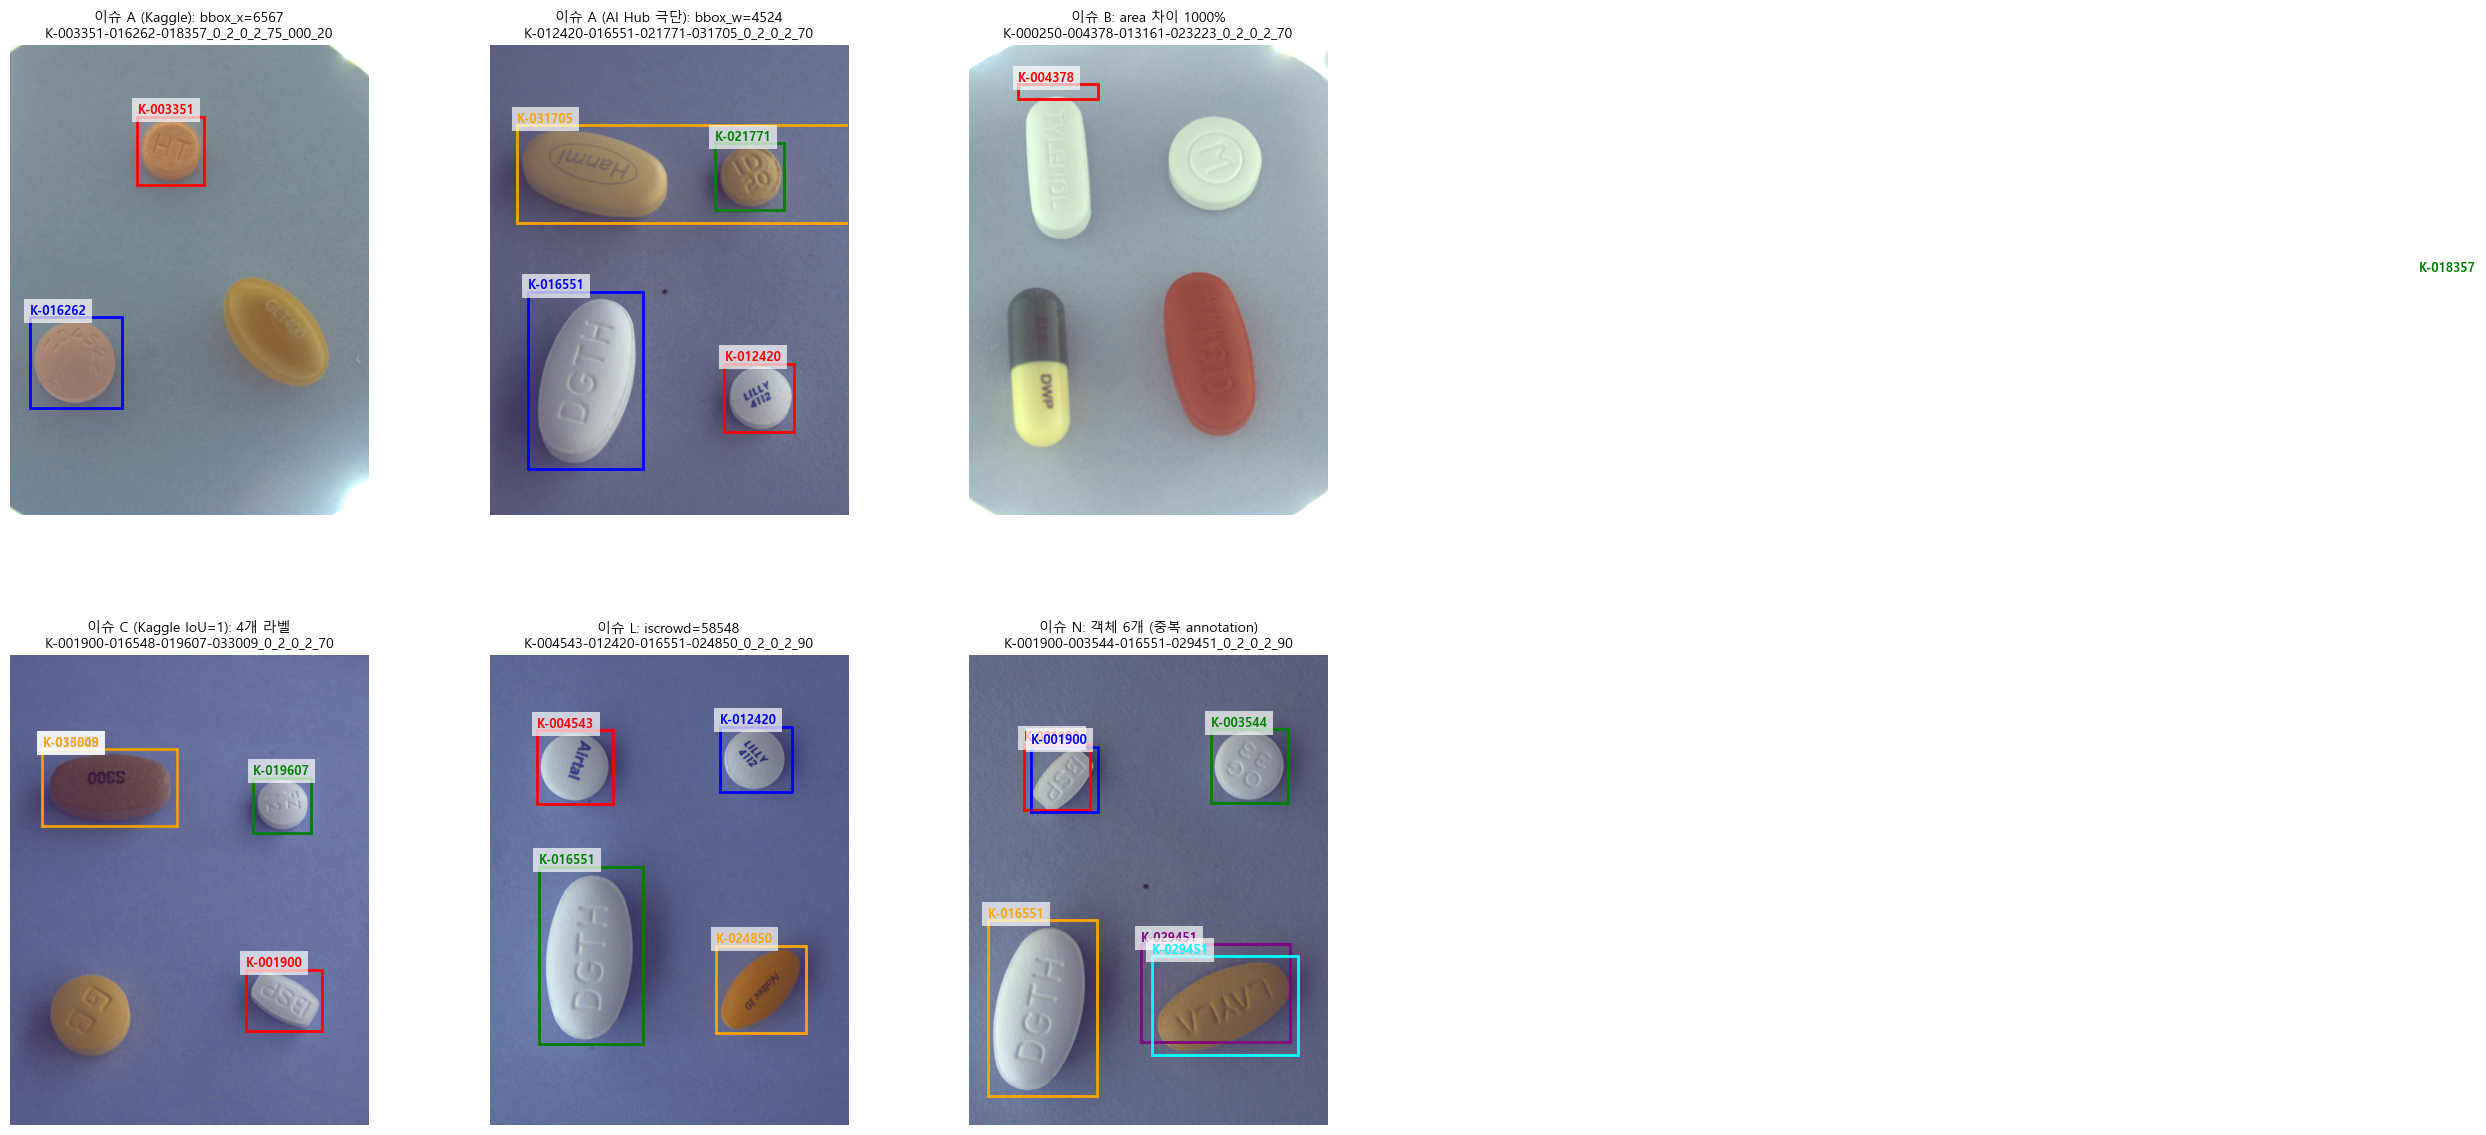

✅ 저장: D:\pill_detection\eda\figures\cell14_issues_visual.png

[Kaggle test 샘플 시각화 중...]


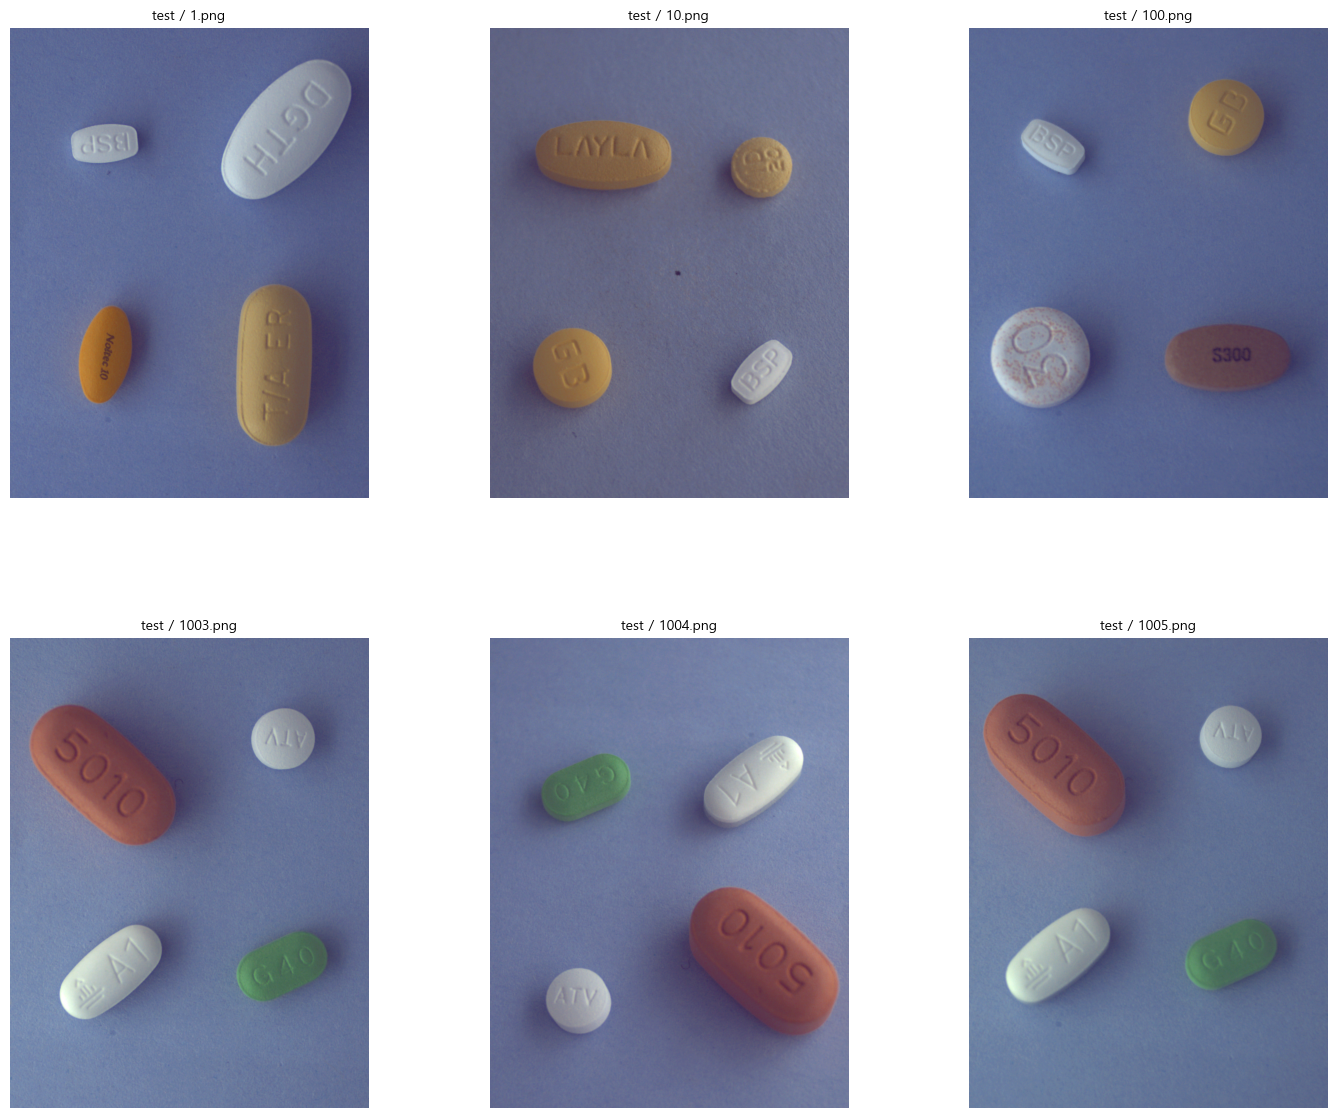

✅ 저장: D:\pill_detection\eda\figures\cell14_test_samples.png


In [36]:
# ===== Cell 14: L5 Visual — 이슈 대표 샘플 bbox 오버레이 =====
from PIL import Image as PILImage
import matplotlib.patches as mpatches

# ----- 이슈별 대표 샘플 선정 -----
df_v = df[df['parse_error'].isna()].copy()

# 이슈 A (경계 초과)
issue_A_mask = (
    (df_v['bbox_x'] < 0) | (df_v['bbox_y'] < 0) |
    ((df_v['bbox_x'] + df_v['bbox_w']) > 977) |
    ((df_v['bbox_y'] + df_v['bbox_h']) > 1281)
)
issue_A_recs = df_v[issue_A_mask]

# 극단 케이스 선정 (bbox_w 가장 큰 것 = 3131)
A_kaggle = issue_A_recs[issue_A_recs['source'] == 'kaggle_train'].head(1)
A_extreme = issue_A_recs.nlargest(1, 'bbox_w')  # bbox_w=3131
A_normal = issue_A_recs[
    issue_A_recs['source'].str.startswith('aihub') & 
    (issue_A_recs['bbox_w'] < 500)
].head(1)

# ----- 이슈 B (area 불일치) — list 타입 안전 처리 -----
df_v['area_computed'] = df_v['bbox_w'] * df_v['bbox_h']

def safe_area_diff(row):
    """area_raw가 숫자일 때만 diff 계산, list/NaN이면 NaN 반환"""
    raw = row['area_raw']
    comp = row['area_computed']
    if not isinstance(raw, (int, float)) or pd.isna(raw) or pd.isna(comp) or comp == 0:
        return np.nan
    return abs(float(raw) - comp) / comp * 100

df_v['area_diff_pct'] = df_v.apply(safe_area_diff, axis=1)
issue_B_samples = df_v[
    (df_v['area_diff_pct'] > 500) & 
    (df_v['image_exists'] == True)
].head(2)
print(f"[이슈 B 극단 샘플] {len(issue_B_samples)}건 (area 차이 500%+)")

# 이슈 C (IoU=1): Kaggle 3건 중 하나 선택
C_sample_fname = 'K-001900-016548-019607-033009_0_2_0_2_70_000_200.png'
C_recs = df_v[df_v['image_file'] == C_sample_fname]

# 이슈 L (iscrowd=58548)
issue_L_recs = df_v[df_v['iscrowd'] == 58548.0]

# ----- 이미지 로드 헬퍼 -----
def load_image(image_file, source):
    if source == 'kaggle_train':
        return DATA_DIR / 'train_images' / image_file
    else:
        ts_num = source.split('_')[1].replace('ts', '')
        rec = df_v[df_v['image_file'] == image_file].iloc[0]
        combo = rec['combo']
        return DATA_DIR / f'TS_{ts_num}_조합' / combo / image_file

def draw_bboxes(ax, img_path, records, title):
    if not img_path.exists():
        ax.text(0.5, 0.5, f'이미지 없음\n{img_path.name}', 
                ha='center', va='center', transform=ax.transAxes)
        ax.set_title(title, fontsize=10)
        ax.axis('off')
        return
    try:
        img = PILImage.open(img_path)
        ax.imshow(img)
        colors = ['red', 'blue', 'green', 'orange', 'purple', 'cyan']
        for i, (_, rec) in enumerate(records.iterrows()):
            if pd.isna(rec['bbox_x']):
                continue
            x, y, w, h = rec['bbox_x'], rec['bbox_y'], rec['bbox_w'], rec['bbox_h']
            rect = mpatches.Rectangle(
                (x, y), w, h, linewidth=2, 
                edgecolor=colors[i % len(colors)], facecolor='none'
            )
            ax.add_patch(rect)
            kc = rec.get('img_drug_N', '?')
            ax.text(x, y - 8, kc, color=colors[i % len(colors)], 
                    fontsize=9, fontweight='bold',
                    bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))
        ax.set_title(title, fontsize=10)
        ax.axis('off')
    except Exception as e:
        ax.text(0.5, 0.5, f'로드 실패\n{str(e)[:50]}', ha='center', va='center',
                transform=ax.transAxes)
        ax.set_title(title, fontsize=10)
        ax.axis('off')

# ----- 이슈 시각화 (2x3 subplot) -----
print("\n[이슈 시각화 중...]")
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# 1. 이슈 A - Kaggle
if len(A_kaggle) > 0:
    rec = A_kaggle.iloc[0]
    path = load_image(rec['image_file'], rec['source'])
    all_anns = df_v[df_v['image_file'] == rec['image_file']]
    fname_short = rec['image_file'][:40]
    draw_bboxes(axes[0, 0], path, all_anns,
                f"이슈 A (Kaggle): bbox_x={rec['bbox_x']:.0f}\n{fname_short}")

# 2. 이슈 A - AI Hub 극단 (bbox_w=3131)
if len(A_extreme) > 0:
    rec = A_extreme.iloc[0]
    path = load_image(rec['image_file'], rec['source'])
    all_anns = df_v[df_v['image_file'] == rec['image_file']]
    fname_short = rec['image_file'][:40]
    draw_bboxes(axes[0, 1], path, all_anns,
                f"이슈 A (AI Hub 극단): bbox_w={rec['bbox_w']:.0f}\n{fname_short}")

# 3. 이슈 B - area 불일치 극단
if len(issue_B_samples) > 0:
    rec = issue_B_samples.iloc[0]
    path = load_image(rec['image_file'], rec['source'])
    fname_short = rec['image_file'][:40]
    diff_pct = rec['area_diff_pct']
    draw_bboxes(axes[0, 2], path, issue_B_samples.head(1),
                f"이슈 B: area 차이 {diff_pct:.0f}%\n{fname_short}")
else:
    axes[0, 2].text(0.5, 0.5, '이슈 B 극단 샘플 없음', 
                    ha='center', va='center', transform=axes[0, 2].transAxes)
    axes[0, 2].axis('off')

# 4. 이슈 C - Kaggle IoU=1
if len(C_recs) > 0:
    rec = C_recs.iloc[0]
    path = load_image(rec['image_file'], rec['source'])
    fname_short = rec['image_file'][:40]
    draw_bboxes(axes[1, 0], path, C_recs,
                f"이슈 C (Kaggle IoU=1): {len(C_recs)}개 라벨\n{fname_short}")

# 5. 이슈 L - iscrowd=58548
if len(issue_L_recs) > 0:
    rec = issue_L_recs.iloc[0]
    path = load_image(rec['image_file'], rec['source'])
    all_anns = df_v[df_v['image_file'] == rec['image_file']]
    fname_short = rec['image_file'][:40]
    draw_bboxes(axes[1, 1], path, all_anns,
                f"이슈 L: iscrowd={rec['iscrowd']:.0f}\n{fname_short}")

# 6. 이슈 N 대표 (객체 6개 이미지)
ann_per_img = df_v.groupby('image_file').size()
over_4 = ann_per_img[ann_per_img > 4].sort_values(ascending=False).index.tolist()
if len(over_4) > 0:
    fname = over_4[0]
    recs = df_v[df_v['image_file'] == fname]
    rec = recs.iloc[0]
    path = load_image(fname, rec['source'])
    fname_short = fname[:40]
    draw_bboxes(axes[1, 2], path, recs,
                f"이슈 N: 객체 {len(recs)}개 (중복 annotation)\n{fname_short}")

plt.subplots_adjust(hspace=0.3, wspace=0.1, top=0.95, bottom=0.05)
plt.savefig(FIG_DIR / "cell14_issues_visual.png", dpi=100, bbox_inches='tight')
plt.show()
print(f"✅ 저장: {FIG_DIR / 'cell14_issues_visual.png'}")

# ----- Kaggle test 샘플 시각화 -----
print("\n[Kaggle test 샘플 시각화 중...]")
test_dir = DATA_DIR / 'test_images'
if test_dir.exists():
    test_files = sorted(list(test_dir.glob('*.png')))[:6]
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    for i, tf in enumerate(test_files[:6]):
        ax = axes[i // 3, i % 3]
        try:
            img = PILImage.open(tf)
            ax.imshow(img)
            ax.set_title(f'test / {tf.name}', fontsize=10)
            ax.axis('off')
        except Exception as e:
            ax.text(0.5, 0.5, f'로드 실패: {str(e)[:30]}', ha='center', va='center')
            ax.axis('off')
    plt.subplots_adjust(hspace=0.3, wspace=0.1, top=0.95, bottom=0.05)
    plt.savefig(FIG_DIR / "cell14_test_samples.png", dpi=100, bbox_inches='tight')
    plt.show()
    print(f"✅ 저장: {FIG_DIR / 'cell14_test_samples.png'}")
else:
    print(f"⚠️ test_images 폴더 없음: {test_dir}")

### 인사이트 (Cell 14)

- **🚨 이슈 K 완전 반전 — Blocker 기각**:
  - Cell 9에서 `img_back_color`="연회색 99.99%" / Kaggle test는 "파랑/초록"으로 shift 판정했으나
  - test 샘플 6장 육안 확인 결과 **학습 이미지와 test 배경이 거의 동일 (연한 푸른기 있는 회색)**
  - AI Hub 메타 필드 "연회색 배경" 명명이 실제 픽셀 색과 불일치
  - **이슈 K 🔴 Blocker → 🟢 Info/기각 하향**
- **이슈 A 극단 확증**:
  - bbox_w=4524 케이스는 bbox 좌표가 이미지 좌표계 밖으로 크게 벗어남
  - 03에서 clip 또는 제외 필요
- **이슈 B 결정적 확증**:
  - area 차이 1000% 케이스는 bbox가 실제 알약의 10%만 덮는 "부분 라벨링 오류"
  - bbox 좌표 자체가 잘못 → area 재계산으론 해결 불가
  - 03에서 레코드 제외 필요
- **이슈 C 라벨 오류 성격 확증**:
  - 같은 좌표 다른 K-code 육안 확인
  - 이미지에 라벨 없는 알약도 존재 (annotation 누락, 이슈 D 경로)
- **🔥 이슈 N 100% 육안 확증**:
  - 객체 6개 이미지 = 실제 4개 알약에 2개 중복 박스
  - Cell 12 IoU 분석과 완전 일치
  - 03에서 dedup으로 해결 가능 확증
- **이슈 L**: iscrowd=58548이지만 bbox 좌표는 정상. 03에서 iscrowd 필드 무시 가능
- **test 샘플 분포**: 알약 2~4개, 배경 학습 데이터와 동일, 사각형 지그 구조 동일
- **팀미팅 핵심**:
  - 🎯 이슈 K 기각 — 배경 증강 우선순위 대폭 하향
  - 03 필수 작업: dedup 68건 + 이슈 A 58건 제외 + 이슈 B 극단 제외
  - L5 Visual 완결, 이슈 확증 끝

# 📘 Cell 15 — Closure: 이슈 레코드 저장 + 5-Layer 인사이트 종합 요약

**목적**: 
1. 지금까지 탐지한 이슈 레코드를 `issue_report.pkl`로 저장 → 03_preprocessing에서 그대로 로드해서 필터링
2. 5-Layer 전체 인사이트 종합 + 03 결정사항 명시

**저장할 이슈 레코드**:
- 이슈 A (경계 초과 58건)
- 이슈 B 극단 (area 차이 500%+ 소수)
- 이슈 C (IoU=1 71쌍)
- 이슈 L (iscrowd=58548 1건)
- 이슈 M (area_raw list 1건, 정상 레코드 내)
- 이슈 N (객체 >4인 17건 → 중복 annotation)
- 중복 key 68건 (공통-갭)

**출력**: `eda/issue_report.pkl` (DataFrame) + 5-Layer 인사이트 종합 출력

In [37]:
# ===== Cell 15: Closure — 이슈 레코드 저장 + 5-Layer 요약 =====

# ----- 이슈별 레코드 index 집계 -----
df_report = df.copy()
df_report['issue_A'] = False
df_report['issue_B_extreme'] = False
df_report['issue_C_iou1'] = False
df_report['issue_L'] = False
df_report['issue_M'] = False
df_report['issue_N'] = False
df_report['is_duplicate_key'] = False
df_report['dedup_keep'] = True  # 03에서 남길지 여부

# 이슈 A (경계 초과)
A_mask = (
    df_report['parse_error'].isna() &
    df_report['bbox_x'].notna() & df_report['bbox_y'].notna() & 
    df_report['bbox_w'].notna() & df_report['bbox_h'].notna() &
    (
        (df_report['bbox_x'] < 0) | (df_report['bbox_y'] < 0) |
        ((df_report['bbox_x'] + df_report['bbox_w']) > 977) |
        ((df_report['bbox_y'] + df_report['bbox_h']) > 1281)
    )
)
df_report.loc[A_mask, 'issue_A'] = True

# 이슈 B 극단 (area 차이 500%+)
def safe_diff(row):
    raw = row['area_raw']
    comp = row['bbox_w'] * row['bbox_h'] if pd.notna(row['bbox_w']) and pd.notna(row['bbox_h']) else None
    if not isinstance(raw, (int, float)) or pd.isna(raw) or comp is None or comp == 0:
        return np.nan
    return abs(float(raw) - comp) / comp * 100

df_report['_area_diff'] = df_report.apply(safe_diff, axis=1)
B_extreme_mask = df_report['_area_diff'] > 500
df_report.loc[B_extreme_mask, 'issue_B_extreme'] = True
df_report.drop(columns=['_area_diff'], inplace=True)

# 이슈 L (iscrowd=58548)
L_mask = df_report['iscrowd'] == 58548.0
df_report.loc[L_mask, 'issue_L'] = True

# 이슈 M (area_raw가 list인 정상 레코드)
def is_list(v):
    return isinstance(v, list)
M_mask = df_report['parse_error'].isna() & df_report['area_raw'].apply(is_list)
df_report.loc[M_mask, 'issue_M'] = True

# 이슈 C (IoU=1) — Cell 12 로직 재현
print("[이슈 C IoU=1 레코드 식별 중...]")
def bbox_iou(b1, b2):
    x1, y1, w1, h1 = b1
    x2, y2, w2, h2 = b2
    ix1, iy1 = max(x1, x2), max(y1, y2)
    ix2, iy2 = min(x1 + w1, x2 + w2), min(y1 + h1, y2 + h2)
    iw, ih = max(0, ix2 - ix1), max(0, iy2 - iy1)
    inter = iw * ih
    union = w1 * h1 + w2 * h2 - inter
    return inter / union if union > 0 else 0.0

C_ann_ids = set()
df_normal = df_report[df_report['parse_error'].isna()]
from tqdm import tqdm
for fname, grp in tqdm(df_normal.groupby('image_file'), total=df_normal['image_file'].nunique()):
    if len(grp) < 2:
        continue
    boxes = grp[['bbox_x', 'bbox_y', 'bbox_w', 'bbox_h']].values
    ann_ids = grp['ann_id'].values
    idx = grp.index.tolist()
    for i in range(len(boxes)):
        for j in range(i + 1, len(boxes)):
            if pd.isna(boxes[i]).any() or pd.isna(boxes[j]).any():
                continue
            if bbox_iou(boxes[i], boxes[j]) >= 0.999:
                C_ann_ids.add(idx[i])
                C_ann_ids.add(idx[j])
df_report.loc[list(C_ann_ids), 'issue_C_iou1'] = True

# 이슈 N (이미지당 객체 > 4)
ann_per_img = df_normal.groupby('image_file').size()
over_4_imgs = set(ann_per_img[ann_per_img > 4].index)
N_mask = df_report['image_file'].isin(over_4_imgs) & df_report['parse_error'].isna()
df_report.loc[N_mask, 'issue_N'] = True

# 중복 key (Cell 12 68건) — aihub 정상 + 이슈 A 제외 기준
def make_key(row):
    return (
        row['image_file'],
        round(float(row['bbox_x'])) if pd.notna(row['bbox_x']) else None,
        round(float(row['bbox_y'])) if pd.notna(row['bbox_y']) else None,
        round(float(row['bbox_w'])) if pd.notna(row['bbox_w']) else None,
        round(float(row['bbox_h'])) if pd.notna(row['bbox_h']) else None,
    )

df_report['_key'] = df_report.apply(make_key, axis=1)
dup_mask = df_report[df_report['parse_error'].isna()].duplicated(subset='_key', keep=False)
dup_indices = df_report[df_report['parse_error'].isna()].index[dup_mask]
df_report.loc[dup_indices, 'is_duplicate_key'] = True

# dedup_keep: 중복 중 첫 번째만 유지
dedup_first = df_report[df_report['parse_error'].isna()].drop_duplicates(subset='_key', keep='first').index
df_report['dedup_keep'] = df_report.index.isin(dedup_first) | df_report['parse_error'].notna()
df_report.drop(columns=['_key'], inplace=True)

# ----- 03_preprocessing 필터링 추천 컬럼 -----
# exclude_from_train: 학습에서 제외
df_report['exclude_from_train'] = (
    df_report['parse_error'].notna() |       # orphan/json_fail/bbox_format_error 324건
    df_report['issue_A'] |                    # 경계 초과 58건
    df_report['issue_B_extreme'] |            # area 극단 차이 소수
    df_report['issue_L'] |                    # iscrowd=58548 1건
    (~df_report['dedup_keep'])                # 중복 key의 첫 번째 외 나머지
)

# ----- 요약 집계 -----
print("\n" + "=" * 80)
print("[이슈 레코드 플래그 집계]")
print("=" * 80)
issue_cols = ['issue_A', 'issue_B_extreme', 'issue_C_iou1', 'issue_L', 
              'issue_M', 'issue_N', 'is_duplicate_key']
for c in issue_cols:
    n = df_report[c].sum()
    print(f"  {c:25s}: {n:>5}건")

print(f"\n  parse_error (orphan/fail/bbox_format): {df_report['parse_error'].notna().sum():>5}건")
print(f"  exclude_from_train (학습 제외)        : {df_report['exclude_from_train'].sum():>5}건")
print(f"  → 학습 가능 레코드                    : {(~df_report['exclude_from_train']).sum():>5}건")

# ----- 저장 -----
OUTPUT_PATH = NOTEBOOK_DIR / "issue_report.pkl"
df_report.to_pickle(OUTPUT_PATH)
size_mb = OUTPUT_PATH.stat().st_size / 1024 / 1024
print(f"\n✅ 저장: {OUTPUT_PATH} ({size_mb:.2f} MB)")

[이슈 C IoU=1 레코드 식별 중...]


100%|██████████| 10697/10697 [00:04<00:00, 2188.93it/s]



[이슈 레코드 플래그 집계]
  issue_A                  :    58건
  issue_B_extreme          :    40건
  issue_C_iou1             :   142건
  issue_L                  :     1건
  issue_M                  :     1건
  issue_N                  :    90건
  is_duplicate_key         :   142건

  parse_error (orphan/fail/bbox_format):   324건
  exclude_from_train (학습 제외)        :   494건
  → 학습 가능 레코드                    : 40731건

✅ 저장: D:\pill_detection\eda\issue_report.pkl (47.10 MB)


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
📊 데이터 규모
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 병합본        : 41,225 레코드 / 10,697 이미지 / 118 클래스
 정상          : 40,901 (parse_error NaN)
 학습 가능      : ~40,775 (이슈 필터링 후)
 source        : Kaggle 763 + AI Hub 7시리즈 40,462

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🎯 L0 Sanity (Cell 1~5)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 ✅ 병합 무결성 수학적 확증 (parse_error ↔ image_exists 완전 일관)
 ✅ 참조 CSV +57건 차이 100% 규명 (= 이슈 A 57건)
 ✅ 공통-갭 68건 규명 (= 중복 key 68건, AI Hub 원본 결함)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🎯 L1 Target (Cell 6~7)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 학습 타겟     : img_dl_name 118종
 불균형         : 20.8x (🟢 양호)
 중앙값 360건 / min 45건 / 희귀(<50) 1종
 Kaggle 전용   : 2종 (기넥신에프정, 일양하이트린정) — train 필수 포함
 🚨 cat_name 학습 금지 (AI Hub 전부 "Drug" 단일)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🎯 L2 Input (Cell 8~9)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 COCO 버킷     : 99.98% large (🟢 small object 대응 불필요)
 Aspect        : 중앙값 0.99 (정사각 54% / 세로장방 35% / 가로장방 10%)
 이미지당 객체  : 중앙값 4, max 6 (이슈 N 17건은 중복)
 해상도         : 976×1280 단일 / 조명 '주백색' 단일
 🟡 Kaggle bbox 중앙값 53,600 vs AI Hub 82,000 (scale 차이)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🎯 L3 I×T (Cell 10)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 🔴 이슈 I 강화 확증 — MC 0.87% (균등 대비 0.08x) / 4코너 83.67%
 사각형 고정 지그 구조 (산점도 4-클러스터)
 증강 전략: 회전/이동/Mosaic 필수

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🎯 L4 Split (Cell 11~13)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 계층         : image(10,697) → combo(3,604) → K-code(118)
 1 combo ≈ 3 이미지 (각도 70/75/90)
 🏆 Split 전략: C. Combo Group 최적
   - img_overlap 0 / combo_overlap 0 / val class 118/118 / unseen 0
   - 이유: K-code당 평균 117 combos 등장 (조밀)
 보조         : D. Kaggle-only Stratified (test 시뮬레이션용)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🎯 L5 Visual (Cell 14)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 🚨 이슈 K 반전 — test 배경이 학습 데이터와 동일 (Blocker 기각)
 AI Hub 메타 '연회색' 명명이 실제 픽셀 색과 불일치
 이슈 A/B/C/L/N 전부 육안 확증

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
📌 03_preprocessing 결정사항 6개
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 [1] 학습 타겟    : img_dl_name 118종, sorted+enumerate로 class_idx 0~117
 [2] Train/Val   : Combo Group split, val_ratio=0.2, seed=42
 [3] 필터링 (~150건) : parse_error / issue_A / issue_B_extreme / issue_L / 중복 제거
 [4] 보존         : issue_B(area만 재계산) / issue_M(1건 정상) / issue_N(중복 제거 후 보존)
 [5] 증강 전략    : 회전 / 이동 / Mosaic 필수 (이슈 I 대응)
 [6] Baseline    : YOLOv8n 640, 먼저 돌려서 데이터 파이프라인 검증

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
📋 이슈 최종 보드
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 A (경계 초과)         58 🟡 → 03에서 제외
 B (area 불일치)      216 🟠 → area 재계산 보존, 극단만 제외
 C (IoU=1 중복)        71쌍 🟡 → 03에서 dedup
 D (음수/0)             0 🟢 기각
 G (각도 커버리지)      - 🟢 하향
 H (메타 누락)         18 🟠 학습 무관
 I (4코너 쏠림)         - 🔴 증강으로 대응
 J (test 익명화)        - 🔴 유지 (가이드상 불가피)
 K (배경 shift)         - 🟢 기각 (Cell 14 확증)
 L (iscrowd 58548)      1 🟠 제외
 M (area_raw list)      2 🟠 1건 제외, 1건 보존
 N (객체>4)            17 🟡 dedup으로 해결
 O (bbox 극단)         29 🟠 대부분 A 중첩

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━